# Structural Characteristics (Constructed + Ground-truth)

> **Important: focus on tabular camera-ready output!**

## Pointwise

1. Tree: size
2. Node: depth
3. Node: degree
4. Path: rtl_paths
5. Path: anc_paths

## Pairwise 

1. Node Jaccard Index
   1. _with overview_
3. Path Jaccard Index
   1. _with overview_
4. APTED tree similarity
   1. _with change breakdown_

## Preamble

In [1]:
!cd ../../.. && pip install -v . --group=dev --group=observability --group=analysis

Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
Processing ./.
  Running command installing build dependencies
  Using pip 26.0.1 from /Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/95/9c/c510029fc6ef33a6275cd2c5d3cecd6613dfd6aa401d57c54f1c18852ccf/setuptools-84.0.0-py3-none-any.whl.metadata
    Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
  ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
  torch 2.12.0 requires setuptools<82, but you have setuptools 84.0.0 which is incompatible.
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  r

In [2]:
import warnings

In [3]:
from lxml import etree
import apted

In [4]:
import massi.agents.tools as matls

In [5]:
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

In [6]:
from sklearn.metrics.pairwise import cosine_similarity
COS_SIMILARITY_READY = False
try:
    # NOTE: this can not run natively on Intel mac anymore
    from sentence_transformers import SentenceTransformer
    COS_SIMILARITY_READY = True
except ImportError as e:
    COS_SIMILARITY_READY = False
    warnings.warn("FAILED TO IMPORT `sentence_transformers`")
    warnings.warn(str(e))
finally:
    print(f"{COS_SIMILARITY_READY=}")

COS_SIMILARITY_READY=True


In [7]:
import tol_colors as tcls

In [8]:
import itertools as itlx
import json
from pathlib import Path
import re 

In [9]:
from typing import TypedDict, Any

In [10]:
from IPython.display import display, display_markdown

In [11]:
from pprint import pprint

In [12]:
tcls.set_default_colors()
plt.set_cmap(mpl.cm.tab20)

New config line: axes.prop_cycle : cycler('color', ['4477AA', 'EE6677', '228833', 'CCBB44', '66CCEE', 'AA3377', 'BBBBBB'])
Injecting line in file '/Users/mitjaorlov/.matplotlib/matplotlibrc'


<Figure size 640x480 with 0 Axes>

### Utilities

In [13]:
from warnings import warn

class OutcomeContainer[T](TypedDict):
    value: T | None
    error: str | None

def do_or_error(func) -> OutcomeContainer[Any]: 
    def wrapper(*args, **kwargs):
        try:
            return {"value": func(*args, **kwargs), "error": None}
        except Exception as e:
            return {"error": f"{type(e)}: {str(e)}", "value": None}
    return wrapper

def do_on_value(func):
    def wrapper(c: OutcomeContainer[Any], *args, **kwargs):
        if c["value"] is not None:
            return func(c["value"], *args, **kwargs)
        else:
            return c
    return wrapper

In [14]:
EXPERIMENT_BASE_DIR = "../../../_data/gbif_data_archive/"

def grounded_path(suffix: str | Path) -> Path:
    return Path(EXPERIMENT_BASE_DIR) / suffix

In [15]:
def ok_results(df):
    return df[df["success"]]

### Constructs

In [16]:
@do_or_error
def parse_xml_file(path: str | Path):
    return etree.parse(path)

@do_or_error
def parse_xml_string(data: str):
    return etree.fromstring(data.encode())

@do_on_value
def parse_xml_content(xml_content: Any):
    return parse_xml_string(str(xml_content))

In [17]:
@do_or_error
def resolve_xml_content(r: dict) -> str:
    return r['resolutions'][0]['working_copy_xml_blueprint']["content"]    

In [18]:
@do_on_value
@do_or_error
def cleanup_gap_failures(xml_data:str):
    return re.sub(r"\{\{GAP_([0-9]+)[^\}]*\}+", r"not-derived-\1", xml_data)

@do_on_value
@do_or_error
def cleanup_special_characters(xml_data:str):
    return re.sub("&", "&amp;", xml_data)

In [19]:
class NodeInfo(TypedDict):
    tag: str
    degree: int
    depth: int
    is_leaf: bool # <=> (degree == 0) 
    attributes: str # <-- json.dumps(attributes)
    attributes_count: int # <-- |attributes.keys()|
    text: str
    path: str | None

class TreeInfo(TypedDict):
    size: int # <-- |_nodes|
    size_with_attributes: int # <-- SUM(n.attributes_count for n in _nodes)
    _nodes: list[NodeInfo]

def project_public(d: dict):
    public_data = {k:v for k,v in d.items() if not str(k).startswith("_")}
    return public_data

In [20]:
def get_root(tree):
    """Retrieves a root of the provided tree"""
    if hasattr(tree, "getroot"):
        return tree.getroot()
    return tree

In [21]:
@do_on_value
@do_or_error
def get_tree_info(tree) -> TreeInfo:
    return _get_tree_info(tree)

def _get_tree_info(tree) -> TreeInfo:
    root = etree.ElementTree(get_root(tree))
    
    def _get_node_info(node) -> NodeInfo:
        return {
            "tag": node.tag,
            "depth": len(list(node.iterancestors())),
            "degree": len(node),
            "is_leaf": len(node) == 0,
            "attributes": json.dumps(dict(node.attrib.items())),
            "attributes_count": len(node.attrib.keys()),
            "has_attributes": bool(node.attrib),
            "text": node.text,
            "has_text": bool(node.text.strip()) if node.text else False,
            "path": None if isinstance(node, etree._Comment) else root.getelementpath(node)
        }
    
    nodes_info = list(map(_get_node_info, root.iter()))
    return {
        "size": len(nodes_info), 
        "size_with_attributes": len(nodes_info) + sum(n["attributes_count"] for n in nodes_info),
        "_nodes": nodes_info
    }

## Data collection

In [22]:
gbif_cases = pd.read_csv("../../runtime/full_gbif_cases.csv")
experiment_results = pd.read_csv("../../runtime/experiment_cross_scenarios_cases.log.csv")

In [23]:
dwc_data_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "data-focus")]
dwc_author_results = experiment_results[(experiment_results["schema"] == "dwc") & (experiment_results["strategy"] == "author-focus")]

eml_data_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "data-focus")]
eml_author_results = experiment_results[(experiment_results["schema"] == "eml") & (experiment_results["strategy"] == "author-focus")]

In [24]:
import json

json.loads(dwc_data_results[dwc_data_results["case_id"] == 59]["outcome_json"].tolist()[0])

{'messages': [],
 'settings': {'runtime_config': {'output_directory': '_data/gbif_data_archive/out/c_59-x-s_0',
   'working_directory': '_data/gbif_data_archive/working_copy/data/068-00c0e9d7-8442-37c0-96de-ae2cf9473a2b-download-data'}},
 'goals': [{'level': 1,
   'scopes': ['descriptive', 'technical', 'use'],
   'target_filename': 'meta.xml',
   'schema_source': 'https://dwc.tdwg.org/text/tdwg_dwc_text.xsd',
   'description': 'This metadata file describes the archive and data file structure.A descriptor metafile describes how the files in your archive are organized.It describes the files in the archive and maps each data column to a corresponding standard Darwin Core or Extension term.The metafile is a relatively simple XML file format.',
   'metadata_goal_key': 'darwin_core'}],
 'dataset': {'files': [{'location': '/Users/dmitriiorlov/Projects/_phd/_workbench/_tech/miagis-assistant/_data/gbif_data_archive/working_copy/data/068-00c0e9d7-8442-37c0-96de-ae2cf9473a2b-download-data/occurre

In [25]:
result_groups = {
    "DwC-T~Data": dwc_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
    "DwC-T~Author": dwc_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Data": eml_data_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(), 
    "EML~Author": eml_author_results.sort_values(by="short_scenario_x_case_tag").copy().reset_index(),
}
result_group_2_ground_truth = {
    "DwC-T~Data": "ground_truth_metadata_dwc",
    "DwC-T~Author": "ground_truth_metadata_dwc", 
    "EML~Data": "ground_truth_metadata_eml", 
    "EML~Author": "ground_truth_metadata_eml",
}
cross_group_key_pairs = {
    ("DwC-T~Data", "DwC-T~Author"),
    ("EML~Data", "EML~Author"),
}

for g, rs in result_groups.items():
    display(f"> --- Result Group: `{g}` ---")
    display(rs.describe())

'> --- Result Group: `DwC-T~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,164.296089,0.0,0.0,153.513966,2.0,89.000000,46.359027,1.778160e+09
std,99.617169,0.0,0.0,99.156009,0.0,51.816986,77.392903,1.187505e+04
min,0.000000,0.0,0.0,0.000000,2.0,0.000000,12.870421,1.778149e+09
25%,84.500000,0.0,0.0,68.000000,2.0,44.500000,22.477583,1.778155e+09
50%,159.000000,0.0,0.0,151.000000,2.0,89.000000,30.010789,1.778159e+09
75%,263.500000,0.0,0.0,233.500000,2.0,133.500000,43.288641,1.778165e+09
max,444.000000,0.0,0.0,336.000000,2.0,178.000000,765.560462,1.778260e+09


'> --- Result Group: `DwC-T~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,194.670391,4.0,4.0,153.513966,2.0,89.000000,42.249969,1.778161e+09
std,109.385350,0.0,0.0,99.156009,0.0,51.816986,54.813842,1.193789e+04
min,10.000000,4.0,4.0,0.000000,2.0,0.000000,14.248861,1.778150e+09
25%,114.500000,4.0,4.0,68.000000,2.0,44.500000,24.495313,1.778156e+09
50%,189.000000,4.0,4.0,151.000000,2.0,89.000000,29.604584,1.778160e+09
75%,310.500000,4.0,4.0,233.500000,2.0,133.500000,42.310426,1.778167e+09
max,445.000000,4.0,4.0,336.000000,2.0,178.000000,478.510206,1.778260e+09


'> --- Result Group: `EML~Data` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,515.670391,8.0,8.0,153.513966,2.0,89.000000,445.775805,1.778304e+09
std,97.111935,0.0,0.0,99.156009,0.0,51.816986,394.417847,3.889963e+04
min,354.000000,8.0,8.0,0.000000,2.0,0.000000,38.520714,1.778230e+09
25%,439.500000,8.0,8.0,68.000000,2.0,44.500000,312.525535,1.778249e+09
50%,527.000000,8.0,8.0,151.000000,2.0,89.000000,407.317098,1.778325e+09
75%,611.500000,8.0,8.0,233.500000,2.0,133.500000,496.024076,1.778331e+09
max,702.000000,8.0,8.0,336.000000,2.0,178.000000,4997.299114,1.778334e+09


'> --- Result Group: `EML~Author` ---'

,index,Unnamed: 0_x,scenario_id,Unnamed: 0_y,data_standard,case_id,duration_seconds,timestamp
count,179.000000,179.0,179.0,179.000000,179.0,179.000000,179.000000,1.790000e+02
mean,555.363128,12.0,12.0,153.513966,2.0,89.000000,261.103811,1.778308e+09
std,108.616256,0.0,0.0,99.156009,0.0,51.816986,67.038688,3.772579e+04
min,356.000000,12.0,12.0,0.000000,2.0,0.000000,51.728838,1.778231e+09
25%,480.500000,12.0,12.0,68.000000,2.0,44.500000,221.043937,1.778322e+09
50%,567.000000,12.0,12.0,151.000000,2.0,89.000000,264.250012,1.778327e+09
75%,666.500000,12.0,12.0,233.500000,2.0,133.500000,305.515517,1.778333e+09
max,715.000000,12.0,12.0,336.000000,2.0,178.000000,466.105851,1.778335e+09


In [26]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_dict"] = rs["outcome_json"].apply(json.loads)
result_groups[g]["outcome_dict"].head()

0    {'messages': [], 'settings': {'runtime_config'...
1    {'status': 'exception', 'error_content': ''gap...
2    {'messages': [], 'settings': {'runtime_config'...
3    {'messages': [], 'settings': {'runtime_config'...
4    {'messages': [], 'settings': {'runtime_config'...
Name: outcome_dict, dtype: object

In [27]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml"] = rs["outcome_dict"].apply(resolve_xml_content)
result_groups[g]["outcome_metadata_xml"].head()

0    {'value': '<?xml version="1.0" encoding="UTF-8...
1    {'error': '<class 'KeyError'>: 'resolutions'',...
2    {'value': '<?xml version="1.0" encoding="UTF-8...
3    {'value': '<?xml version="1.0" encoding="UTF-8...
4    {'value': '<?xml version="1.0" encoding="UTF-8...
Name: outcome_metadata_xml, dtype: object

In [28]:
for g, rs in result_groups.items():
    result_groups[g]["outcome_metadata_xml.clean"] = rs["outcome_metadata_xml"].apply(cleanup_gap_failures).apply(cleanup_special_characters)
    result_groups[g]["constructed.xml_tree"] = result_groups[g]["outcome_metadata_xml.clean"].apply(parse_xml_content)
result_groups[g]["outcome_metadata_xml.clean"].head(), result_groups[g]["constructed.xml_tree"].head()

(0    {'value': '<?xml version="1.0" encoding="UTF-8...
 1    {'error': '<class 'KeyError'>: 'resolutions'',...
 2    {'value': '<?xml version="1.0" encoding="UTF-8...
 3    {'value': '<?xml version="1.0" encoding="UTF-8...
 4    {'value': '<?xml version="1.0" encoding="UTF-8...
 Name: outcome_metadata_xml.clean, dtype: object,
 0    {'value': [[<Element title at 0x11dc00380>, <E...
 1    {'error': '<class 'KeyError'>: 'resolutions'',...
 2    {'value': [[<Element title at 0x11dc00380>, <E...
 3    {'value': [[<Element title at 0x11dc00480>, <E...
 4    {'value': [[<Element title at 0x11dc004c0>, <E...
 Name: constructed.xml_tree, dtype: object)

In [29]:
def with_ok_constructed_trees(df):
    return df[df["constructed.xml_tree"].apply(lambda x: x["value"] is not None)]

def with_ok_ground_truth_trees(df):
    return df[df["ground_truth.xml_tree"].apply(lambda x: x["value"] is not None)]

In [30]:
for g, rs in result_groups.items():
    gt_key = result_group_2_ground_truth[g]
    result_groups[g]["ground_truth.xml_tree"] = rs[gt_key].apply(grounded_path).apply(parse_xml_file)
result_groups[g]["ground_truth.xml_tree"].head()

0    {'value': <lxml.etree._ElementTree object at 0...
1    {'value': <lxml.etree._ElementTree object at 0...
2    {'value': <lxml.etree._ElementTree object at 0...
3    {'value': <lxml.etree._ElementTree object at 0...
4    {'value': <lxml.etree._ElementTree object at 0...
Name: ground_truth.xml_tree, dtype: object

In [31]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(result_groups[g].shape[0])
    print(with_ok_constructed_trees(result_groups[g]).shape[0])
    print(ok_results(result_groups[g]).shape[0])

--- DwC-T~Data ---
179
174
179
--- DwC-T~Author ---
179
174
175
--- EML~Data ---
179
150
155
--- EML~Author ---
179
148
158


## Computing Individual Values

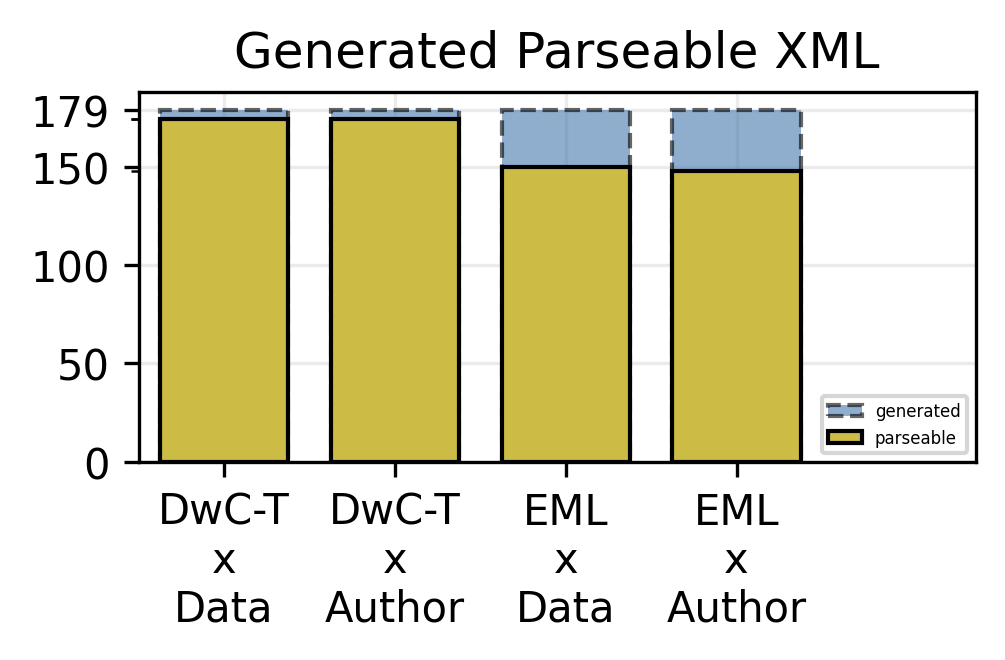

In [32]:
fig, ax = plt.subplots(1,1, dpi=300, figsize=(3.6, 1.6))

experiment_groups = np.array(["\nx\n".join(g.split("~")) for g, rs in result_groups.items()])
experiment_count = np.array([rs.shape[0] for g, rs in result_groups.items()])
ok_experiment_count = np.array([with_ok_constructed_trees(rs).shape[0] for g, rs in result_groups.items()])

ax.set_title("Generated Parseable XML")
ax.bar(experiment_groups, experiment_count, label="generated", color=tcls.bright[0], edgecolor="black", ls="--", alpha=0.6, width=0.75)
ax.bar(experiment_groups, ok_experiment_count, label="parseable", color=tcls.bright[3], edgecolor="black", width=0.75)
ax.set_yticks(ok_experiment_count, minor=True)
ax.set_yticks([0, 50, 100, 150, 179])
ax.set_xlim(-0.5, 4.4)
ax.legend(fontsize=4, loc="lower right")
ax.grid(alpha=0.25)
ax.set_axisbelow(True)

In [33]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.characteristics"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(get_tree_info)
result_groups[g]["constructed.xml_tree.characteristics"].head()[0]

{'value': {'size': 47,
  'size_with_attributes': 55,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43", "system": "knb", "{http://www.w3.org/XML/1998/namespace}lang": "en"}',
    'attributes_count': 3,
    'has_attributes': True,
    'text': '\n  ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 6,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n    ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'title',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': 'Renato_PhD',
    'has_text': True,
    'path': 'dataset/title'},
   {'tag': 'creator',
    'depth': 2,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{}',
   

In [34]:
for g, rs in result_groups.items():
    result_groups[g]["ground_truth.xml_tree.characteristics"] = rs["ground_truth.xml_tree"].apply(get_tree_info)
result_groups[g]["ground_truth.xml_tree.characteristics"].head()[0]

{'value': {'size': 511,
  'size_with_attributes': 527,
  '_nodes': [{'tag': '{https://eml.ecoinformatics.org/eml-2.2.0}eml',
    'depth': 0,
    'degree': 2,
    'is_leaf': False,
    'attributes': '{"{http://www.w3.org/2001/XMLSchema-instance}schemaLocation": "https://eml.ecoinformatics.org/eml-2.2.0 https://rs.gbif.org/schema/eml-gbif-profile/1.3/eml.xsd", "packageId": "2265c6e2-4ab7-4af2-93af-ba377a7d4e43/v1.2", "system": "http://gbif.org", "scope": "system", "{http://www.w3.org/XML/1998/namespace}lang": "eng"}',
    'attributes_count': 5,
    'has_attributes': True,
    'text': '\n    ',
    'has_text': False,
    'path': '.'},
   {'tag': 'dataset',
    'depth': 1,
    'degree': 26,
    'is_leaf': False,
    'attributes': '{}',
    'attributes_count': 0,
    'has_attributes': False,
    'text': '\n        ',
    'has_text': False,
    'path': 'dataset'},
   {'tag': 'alternateIdentifier',
    'depth': 2,
    'degree': 0,
    'is_leaf': True,
    'attributes': '{}',
    'attributes_c

### Constructed


In [35]:
cons_tree_info_groups = {}
cons_node_info_groups = {}
for g, rs in result_groups.items():
    cons_tree_info_groups[g] = pd.DataFrame.from_records(
        with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["constructed.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    cons_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(with_ok_constructed_trees(result_groups[g]).apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["constructed.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [36]:
list([(g,vs["constructed.xml_tree"]) for g,vs in result_groups.items()])

[('DwC-T~Data',
  0      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  1      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  2      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  3      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  4      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
                               ...                        
  174    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  175    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  176    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  177    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  178    {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  Name: constructed.xml_tree, Length: 179, dtype: object),
 ('DwC-T~Author',
  0      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  1      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  2      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  3      {'value': [[<Element {http://rs.tdwg.org/dwc/t...
  4      {'value': [[<

In [37]:
for g,rs in cons_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.356322,49.149425,142.752874
std,52.318163,22.960649,68.108990
min,0.000000,12.000000,33.000000
25%,43.250000,33.250000,97.500000
50%,90.500000,45.000000,132.000000
75%,134.750000,60.750000,175.750000
max,178.000000,190.000000,565.000000


DwC-T~Author


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.350575,49.206897,142.885057
std,51.515395,22.552771,67.131124
min,0.000000,12.000000,33.000000
25%,45.250000,34.000000,99.000000
50%,89.500000,45.500000,133.000000
75%,133.750000,61.000000,176.000000
max,178.000000,186.000000,555.000000


EML~Data


,case_id,size,size_with_attributes
count,150.000000,150.000000,150.000000
mean,88.686667,42.460000,50.266667
std,53.070314,9.766145,11.063372
min,0.000000,32.000000,37.000000
25%,42.250000,34.000000,41.000000
50%,88.500000,41.000000,49.000000
75%,134.750000,48.000000,57.000000
max,178.000000,76.000000,86.000000


EML~Author


,case_id,size,size_with_attributes
count,148.000000,148.000000,148.000000
mean,92.864865,40.094595,47.709459
std,50.983477,7.939686,9.134113
min,0.000000,32.000000,37.000000
25%,49.750000,34.000000,41.000000
50%,96.000000,38.000000,46.000000
75%,137.250000,46.000000,54.250000
max,178.000000,65.000000,75.000000


In [38]:
for g,rs in cons_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8552.000000,8552,8552.000000,8552.000000,8552,8552,8552.000000,8552,975,8552,8552
unique,NaN,8,NaN,NaN,2,2928,NaN,2,24,2,332
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7310,NaN,NaN,7844,534,NaN,8018,267,8285,174
mean,88.918732,NaN,1.959308,0.979654,NaN,NaN,1.904467,NaN,NaN,NaN,NaN
std,51.588900,NaN,0.377077,6.206240,NaN,NaN,0.721145,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,43.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,134.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8562.000000,8562,8562.000000,8562.000000,8562,8562,8562.000000,8562,984,8562,8562
unique,NaN,8,NaN,NaN,2,2903,NaN,2,23,2,330
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7308,NaN,NaN,7848,540,NaN,8022,270,8292,174
mean,89.333450,NaN,1.959355,0.979678,NaN,NaN,1.903761,NaN,NaN,NaN,NaN
std,50.609223,NaN,0.377788,6.182620,NaN,NaN,0.720217,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,46.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,6369.000000,6369,6369.000000,6369.000000,6369,6369,6369.000000,6369,6238,6369,6369
unique,NaN,319,NaN,NaN,2,133,NaN,2,1246,2,706
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,697,NaN,NaN,3409,5740,NaN,5740,1258,3433,150
mean,88.133302,NaN,3.396452,0.976448,NaN,NaN,0.183859,NaN,NaN,NaN,NaN
std,53.838807,NaN,1.229222,1.310859,NaN,NaN,0.590399,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,40.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,88.000000,NaN,4.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,135.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,5934.000000,5934,5934.000000,5934.000000,5934,5934,5934.000000,5934,5811,5934,5934
unique,NaN,297,NaN,NaN,2,133,NaN,2,1486,2,558
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,652,NaN,NaN,3194,5327,NaN,5327,1166,3202,148
mean,91.711156,NaN,3.337883,0.975059,NaN,NaN,0.189922,NaN,NaN,NaN,NaN
std,50.854321,NaN,1.219922,1.282741,NaN,NaN,0.601834,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,48.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,92.000000,NaN,3.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,136.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


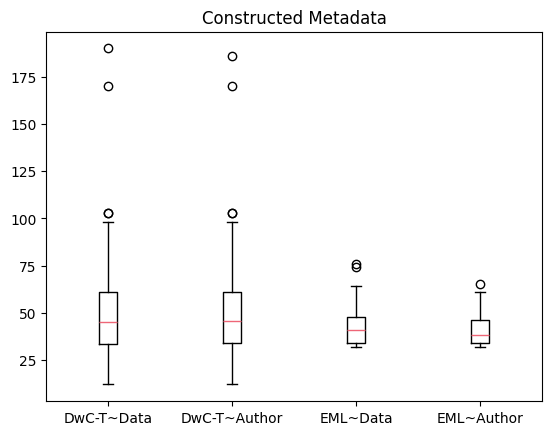

In [39]:
fig,ax = plt.subplots()


ax.set_title("Constructed Metadata")
for i,(g,rs) in enumerate(cons_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

### Ground Truth

In [40]:
gt_tree_info_groups = {}
gt_node_info_groups = {}
for g, rs in result_groups.items():
    gt_tree_info_groups[g] = pd.DataFrame.from_records(
        result_groups[g].apply(
            lambda t: {"case_id": t["case_id"], **project_public(val)} if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else {"case_id": t["case_id"]}, 
            axis=1
        )
    )
    gt_node_info_groups[g] = pd.DataFrame.from_records(
        itlx.chain.from_iterable(result_groups[g].apply(
            lambda t: (
                [
                    {"case_id": t["case_id"], **pn} 
                    for pn 
                    in map(project_public, val["_nodes"])
                ] if (val := t["ground_truth.xml_tree.characteristics"]["value"]) else [{"case_id": t["case_id"]}]
            ), 
            axis=1
        ).tolist())
    )

In [41]:
for g,rs in gt_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


DwC-T~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


EML~Data


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


EML~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


In [42]:
for g,rs in gt_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))

DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


EML~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


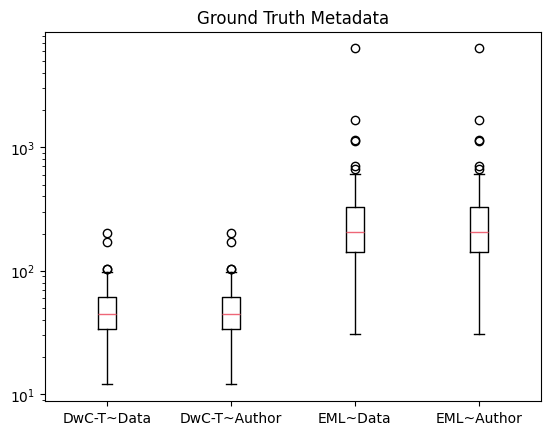

In [43]:
fig,ax = plt.subplots()


ax.set_title("Ground Truth Metadata")
ax.set_yscale("log")
for i,(g,rs) in enumerate(gt_tree_info_groups.items()):
    ax.boxplot(rs["size"].dropna(), positions=(i,), label=g)
ax.set_xticklabels(list(cons_tree_info_groups.keys()))
# ax.legend()

plt.show()

## Reporting Pointwise

In [44]:
def fmt_result_group_title_multiline(t: str)->str:
    return "\nx\n".join(t.split("~"))

def fmt_result_group_title_oneline(t: str)->str:
    return " x ".join(t.split("~"))

In [45]:
for g, rs in result_groups.items():
    print(f"--- {g} ---")
    print(f"total results: {result_groups[g].shape[0]}")
    print(f"parsed_trees: {with_ok_constructed_trees(result_groups[g]).shape[0]}")
    print(f"constructed trees: {ok_results(result_groups[g]).shape[0]}")

--- DwC-T~Data ---
total results: 179
parsed_trees: 174
constructed trees: 179
--- DwC-T~Author ---
total results: 179
parsed_trees: 174
constructed trees: 175
--- EML~Data ---
total results: 179
parsed_trees: 150
constructed trees: 155
--- EML~Author ---
total results: 179
parsed_trees: 148
constructed trees: 158


In [46]:
for ((con_g, con_rs), (gt_g, gt_rs)) in zip(cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    print("---- Sizes ----")
    print(con_g)
    print("Constructed:\t", stats.normaltest(con_rs["size"]))
    print("(LogN):\t\t", stats.normaltest(np.log(con_rs["size"])))
    print(gt_g)
    print("Ground Truth:\t", stats.normaltest(gt_rs["size"]))
    print("(LogN):\t\t", stats.normaltest(np.log(gt_rs["size"])))

---- Sizes ----
DwC-T~Data
Constructed:	 NormaltestResult(statistic=np.float64(117.04517145197084), pvalue=np.float64(3.836753981730182e-26))
(LogN):		 NormaltestResult(statistic=np.float64(3.853635470616972), pvalue=np.float64(0.14561083419492105))
DwC-T~Data
Ground Truth:	 NormaltestResult(statistic=np.float64(130.90239688953477), pvalue=np.float64(3.7575579013227714e-29))
(LogN):		 NormaltestResult(statistic=np.float64(4.830254965363623), pvalue=np.float64(0.08935594685988182))
---- Sizes ----
DwC-T~Author
Constructed:	 NormaltestResult(statistic=np.float64(116.14284784224637), pvalue=np.float64(6.0242229296207e-26))
(LogN):		 NormaltestResult(statistic=np.float64(4.055301765524164), pvalue=np.float64(0.13164440634690128))
DwC-T~Author
Ground Truth:	 NormaltestResult(statistic=np.float64(130.90239688953477), pvalue=np.float64(3.7575579013227714e-29))
(LogN):		 NormaltestResult(statistic=np.float64(4.830254965363623), pvalue=np.float64(0.08935594685988182))
---- Sizes ----
EML~Data
C

### Trees

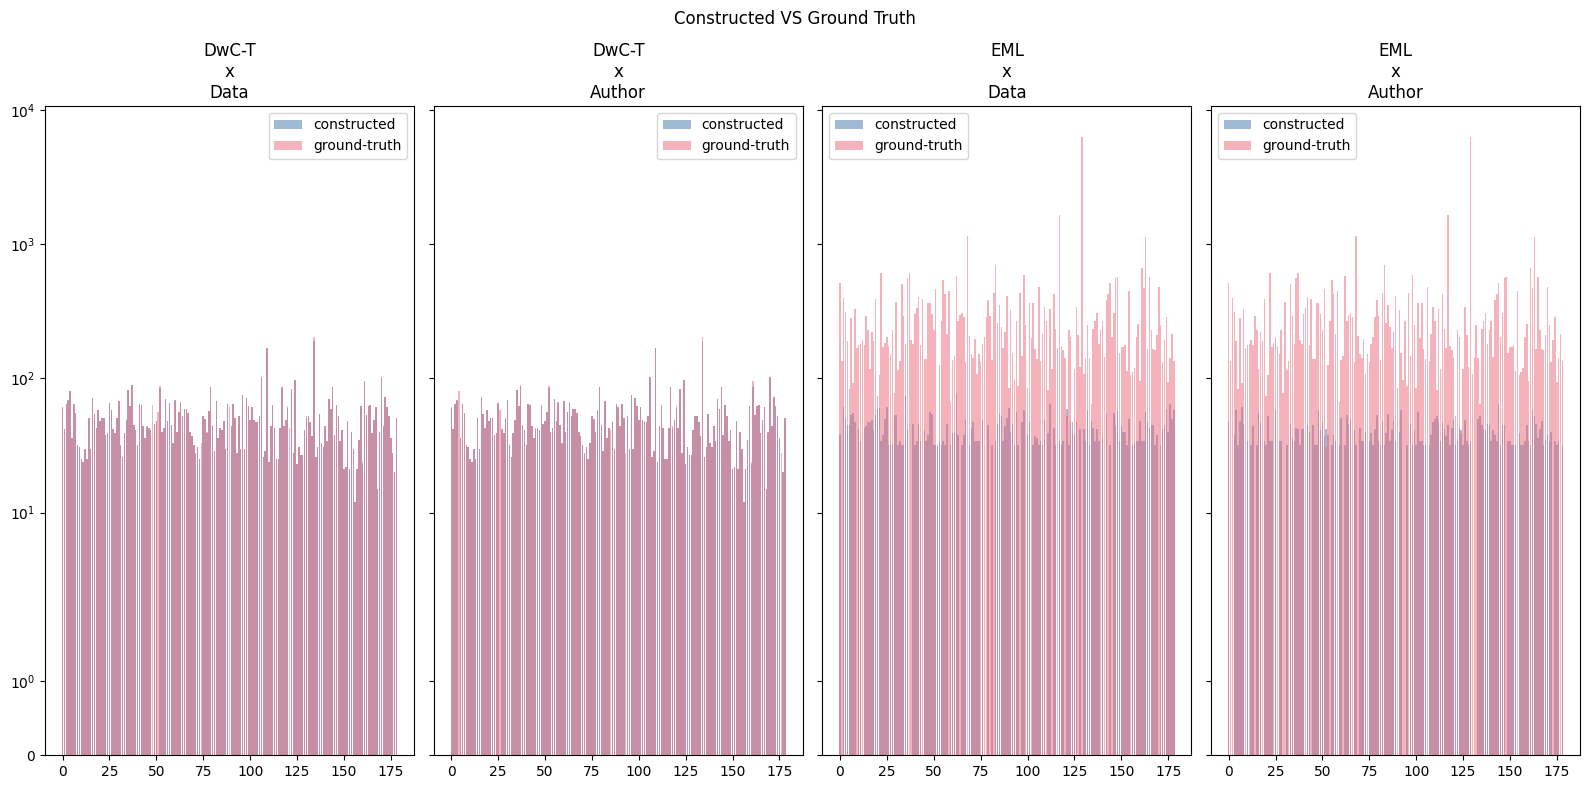

In [47]:
fig, axs = plt.subplots(1, len(cons_tree_info_groups.keys()), figsize=(16,8), sharey=True)

fig.suptitle("Constructed VS Ground Truth")
for (ax, (con_g, con_rs), (gt_g, gt_rs)) in zip(axs, cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    ax.set_yscale("symlog")
    ax.set_title(fmt_result_group_title_multiline(con_g))
    ax.bar(con_rs["case_id"], con_rs["size"], alpha=0.5, label="constructed")
    ax.bar(gt_rs["case_id"], gt_rs["size"], alpha=0.5, label="ground-truth")
    ax.legend()

plt.tight_layout()

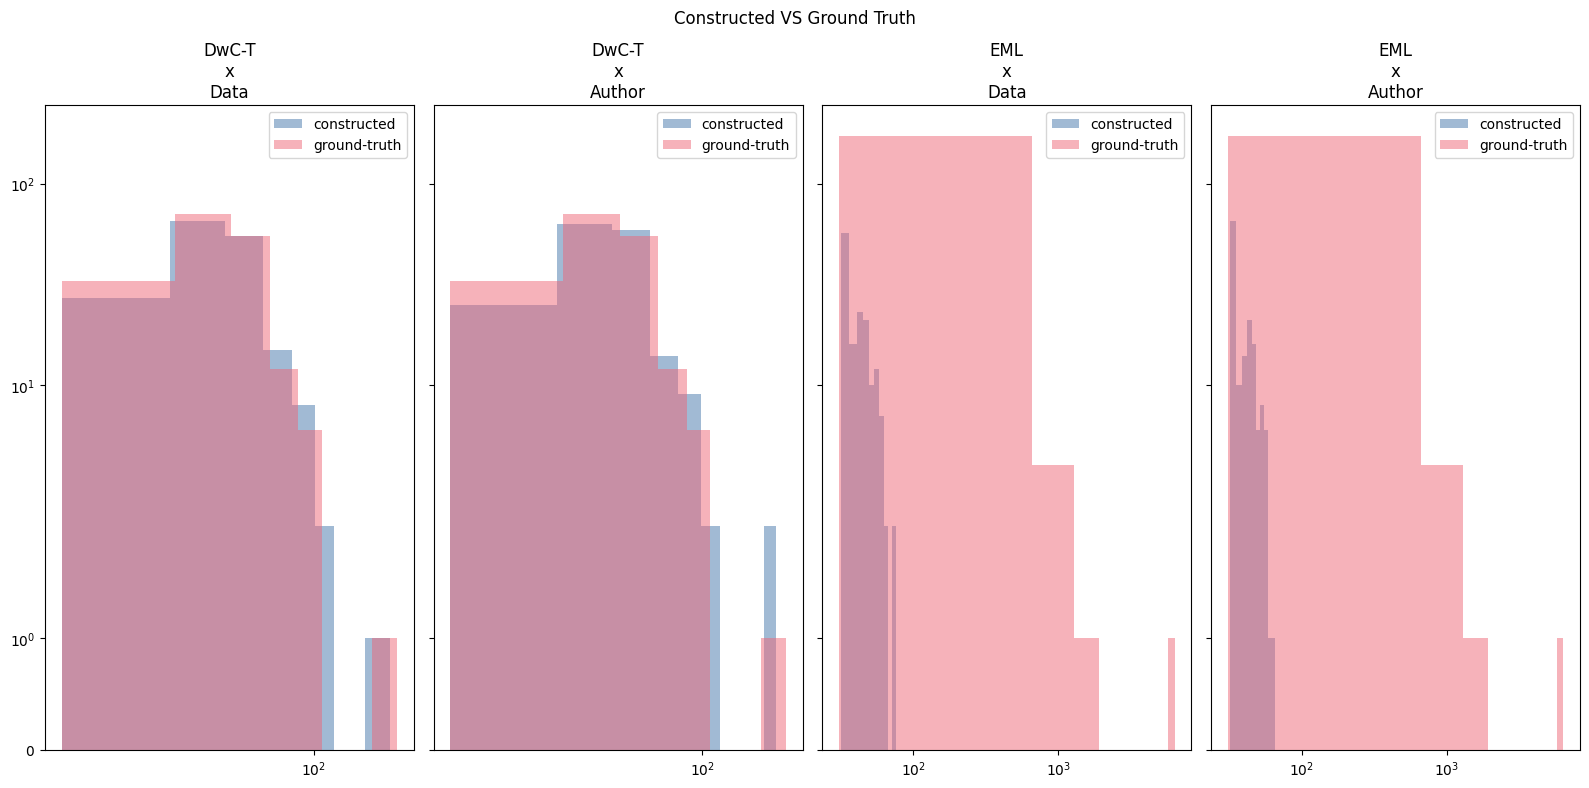

In [48]:
fig, axs = plt.subplots(1, len(cons_tree_info_groups.keys()), figsize=(16,8), sharey=True)

fig.suptitle("Constructed VS Ground Truth")
for (ax, (con_g, con_rs), (gt_g, gt_rs)) in zip(axs, cons_tree_info_groups.items(), gt_tree_info_groups.items()):
    ax.set_yscale("symlog")
    ax.set_xscale("symlog")
    ax.set_title(fmt_result_group_title_multiline(con_g))
    ax.hist(con_rs["size"], alpha=0.5, label="constructed")
    ax.hist(gt_rs["size"], alpha=0.5, label="ground-truth")
    ax.legend()

plt.tight_layout()

In [49]:
print("Constructed Metadata --> Trees")

for g,rs in cons_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Constructed Metadata --> Trees
DwC-T~Data


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.356322,49.149425,142.752874
std,52.318163,22.960649,68.108990
min,0.000000,12.000000,33.000000
25%,43.250000,33.250000,97.500000
50%,90.500000,45.000000,132.000000
75%,134.750000,60.750000,175.750000
max,178.000000,190.000000,565.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 174.000000 & 174.000000 & 174.000000 \\\\\nmean & 89.356322 & 49.149425 & 142.752874 \\\\\nstd & 52.318163 & 22.960649 & 68.108990 \\\\\nmin & 0.000000 & 12.000000 & 33.000000 \\\\\n25% & 43.250000 & 33.250000 & 97.500000 \\\\\n50% & 90.500000 & 45.000000 & 132.000000 \\\\\n75% & 134.750000 & 60.750000 & 175.750000 \\\\\nmax & 178.000000 & 190.000000 & 565.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

DwC-T~Author


,case_id,size,size_with_attributes
count,174.000000,174.000000,174.000000
mean,89.350575,49.206897,142.885057
std,51.515395,22.552771,67.131124
min,0.000000,12.000000,33.000000
25%,45.250000,34.000000,99.000000
50%,89.500000,45.500000,133.000000
75%,133.750000,61.000000,176.000000
max,178.000000,186.000000,555.000000


...

,case_id,size,size_with_attributes
count,150.000000,150.000000,150.000000
mean,88.686667,42.460000,50.266667
std,53.070314,9.766145,11.063372
min,0.000000,32.000000,37.000000
25%,42.250000,34.000000,41.000000
50%,88.500000,41.000000,49.000000
75%,134.750000,48.000000,57.000000
max,178.000000,76.000000,86.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 150.000000 & 150.000000 & 150.000000 \\\\\nmean & 88.686667 & 42.460000 & 50.266667 \\\\\nstd & 53.070314 & 9.766145 & 11.063372 \\\\\nmin & 0.000000 & 32.000000 & 37.000000 \\\\\n25% & 42.250000 & 34.000000 & 41.000000 \\\\\n50% & 88.500000 & 41.000000 & 49.000000 \\\\\n75% & 134.750000 & 48.000000 & 57.000000 \\\\\nmax & 178.000000 & 76.000000 & 86.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

EML~Author


,case_id,size,size_with_attributes
count,148.000000,148.000000,148.000000
mean,92.864865,40.094595,47.709459
std,50.983477,7.939686,9.134113
min,0.000000,32.000000,37.000000
25%,49.750000,34.000000,41.000000
50%,96.000000,38.000000,46.000000
75%,137.250000,46.000000,54.250000
max,178.000000,65.000000,75.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 148.000000 & 148.000000 & 148.000000 \\\\\nmean & 92.864865 & 40.094595 & 47.709459 \\\\\nstd & 50.983477 & 7.939686 & 9.134113 \\\\\nmin & 0.000000 & 32.000000 & 37.000000 \\\\\n25% & 49.750000 & 34.000000 & 41.000000 \\\\\n50% & 96.000000 & 38.000000 & 46.000000 \\\\\n75% & 137.250000 & 46.000000 & 54.250000 \\\\\nmax & 178.000000 & 65.000000 & 75.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

In [50]:
print("Ground Truth Metadata --> Trees")

for g,rs in gt_tree_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Ground Truth Metadata --> Trees
DwC-T~Data


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 179.000000 & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 49.307263 & 145.648045 \\\\\nstd & 51.816986 & 23.171091 & 69.174134 \\\\\nmin & 0.000000 & 12.000000 & 34.000000 \\\\\n25% & 44.500000 & 33.500000 & 98.500000 \\\\\n50% & 89.000000 & 45.000000 & 134.000000 \\\\\n75% & 133.500000 & 61.000000 & 180.000000 \\\\\nmax & 178.000000 & 202.000000 & 603.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

DwC-T~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,49.307263,145.648045
std,51.816986,23.171091,69.174134
min,0.000000,12.000000,34.000000
25%,44.500000,33.500000,98.500000
50%,89.000000,45.000000,134.000000
75%,133.500000,61.000000,180.000000
max,178.000000,202.000000,603.000000


...

,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 179.000000 & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 299.810056 & 318.055866 \\\\\nstd & 51.816986 & 494.601131 & 497.944739 \\\\\nmin & 0.000000 & 31.000000 & 36.000000 \\\\\n25% & 44.500000 & 142.000000 & 153.500000 \\\\\n50% & 89.000000 & 206.000000 & 224.000000 \\\\\n75% & 133.500000 & 331.500000 & 357.500000 \\\\\nmax & 178.000000 & 6326.000000 & 6347.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

EML~Author


,case_id,size,size_with_attributes
count,179.000000,179.000000,179.000000
mean,89.000000,299.810056,318.055866
std,51.816986,494.601131,497.944739
min,0.000000,31.000000,36.000000
25%,44.500000,142.000000,153.500000
50%,89.000000,206.000000,224.000000
75%,133.500000,331.500000,357.500000
max,178.000000,6326.000000,6347.000000


'\\begin{tabular}{lrrr}\n\\toprule\n & case_id & size & size_with_attributes \\\\\n\\midrule\ncount & 179.000000 & 179.000000 & 179.000000 \\\\\nmean & 89.000000 & 299.810056 & 318.055866 \\\\\nstd & 51.816986 & 494.601131 & 497.944739 \\\\\nmin & 0.000000 & 31.000000 & 36.000000 \\\\\n25% & 44.500000 & 142.000000 & 153.500000 \\\\\n50% & 89.000000 & 206.000000 & 224.000000 \\\\\n75% & 133.500000 & 331.500000 & 357.500000 \\\\\nmax & 178.000000 & 6326.000000 & 6347.000000 \\\\\n\\bottomrule\n\\end{tabular}\n'

### Nodes 

In [51]:
# node_cols = ["degree", "depth"]
# fig, axsm = plt.subplots(len(cons_tree_info_groups.keys()), len(node_cols), figsize=(16,8), sharex=True)

# fig.suptitle("Constructed VS Ground Truth")
# for (axs, (con_g, con_rs), (gt_g, gt_rs)) in zip(axsm, cons_node_info_groups.items(), gt_node_info_groups.items()):
#     for (ax, col) in zip(axs, node_cols):
#         ax.set_title(col)
#         if (
#             (max(con_rs[col]) - min(con_rs[col]) > 500)
#             or (max(gt_rs[col]) - min(gt_rs[col]) > 500)
#         ):
#             ax.set_yscale("symlog")
            
#         ax.set_ylabel(fmt_result_group_title_multiline(con_g))
#         ax.bar(con_rs["case_id"], con_rs[col], alpha=0.5)
#         ax.bar(gt_rs["case_id"], gt_rs[col], alpha=0.5)

# plt.tight_layout()

In [52]:
print("Constructed Metadata --> Nodes")

for g,rs in cons_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Constructed Metadata --> Nodes
DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8552.000000,8552,8552.000000,8552.000000,8552,8552,8552.000000,8552,975,8552,8552
unique,NaN,8,NaN,NaN,2,2928,NaN,2,24,2,332
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7310,NaN,NaN,7844,534,NaN,8018,267,8285,174
mean,88.918732,NaN,1.959308,0.979654,NaN,NaN,1.904467,NaN,NaN,NaN,NaN
std,51.588900,NaN,0.377077,6.206240,NaN,NaN,0.721145,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,43.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,134.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 8552.000000 & 8552 & 8552.000000 & 8552.000000 & 8552 & 8552 & 8552.000000 & 8552 & 975 & 8552 & 8552 \\\\\nunique & NaN & 8 & NaN & NaN & 2 & 2928 & NaN & 2 & 24 & 2 & 332 \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}field & NaN & NaN & True & {} & NaN & True & \n     & False & . \\\\\nfreq & NaN & 7310 & NaN & NaN & 7844 & 534 & NaN & 8018 & 267 & 8285 & 174 \\\\\nmean & 88.918732 & NaN & 1.959308 & 0.979654 & NaN & NaN & 1.904467 & NaN & NaN & NaN & NaN \\\\\nstd & 51.588900 & NaN & 0.377077 & 6.206240 & NaN & NaN & 0.721145 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 43.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & 2.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 91.000000 & NaN & 2.000000 & 0.000000 & NaN & N

DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8562.000000,8562,8562.000000,8562.000000,8562,8562,8562.000000,8562,984,8562,8562
unique,NaN,8,NaN,NaN,2,2903,NaN,2,23,2,330
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7308,NaN,NaN,7848,540,NaN,8022,270,8292,174
mean,89.333450,NaN,1.959355,0.979678,NaN,NaN,1.903761,NaN,NaN,NaN,NaN
std,50.609223,NaN,0.377788,6.182620,NaN,NaN,0.720217,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,46.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,91.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


...

,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,6369.000000,6369,6369.000000,6369.000000,6369,6369,6369.000000,6369,6238,6369,6369
unique,NaN,319,NaN,NaN,2,133,NaN,2,1246,2,706
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,697,NaN,NaN,3409,5740,NaN,5740,1258,3433,150
mean,88.133302,NaN,3.396452,0.976448,NaN,NaN,0.183859,NaN,NaN,NaN,NaN
std,53.838807,NaN,1.229222,1.310859,NaN,NaN,0.590399,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,40.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,88.000000,NaN,4.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,135.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 6369.000000 & 6369 & 6369.000000 & 6369.000000 & 6369 & 6369 & 6369.000000 & 6369 & 6238 & 6369 & 6369 \\\\\nunique & NaN & 319 & NaN & NaN & 2 & 133 & NaN & 2 & 1246 & 2 & 706 \\\\\ntop & NaN & para & NaN & NaN & False & {} & NaN & False & \n         & False & . \\\\\nfreq & NaN & 697 & NaN & NaN & 3409 & 5740 & NaN & 5740 & 1258 & 3433 & 150 \\\\\nmean & 88.133302 & NaN & 3.396452 & 0.976448 & NaN & NaN & 0.183859 & NaN & NaN & NaN & NaN \\\\\nstd & 53.838807 & NaN & 1.229222 & 1.310859 & NaN & NaN & 0.590399 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 40.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 88.000000 & NaN & 4.000000 & 1.000000 & NaN & NaN & 0.000000 & NaN 

EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,5934.000000,5934,5934.000000,5934.000000,5934,5934,5934.000000,5934,5811,5934,5934
unique,NaN,297,NaN,NaN,2,133,NaN,2,1486,2,558
top,NaN,para,NaN,NaN,False,{},NaN,False,\n,False,.
freq,NaN,652,NaN,NaN,3194,5327,NaN,5327,1166,3202,148
mean,91.711156,NaN,3.337883,0.975059,NaN,NaN,0.189922,NaN,NaN,NaN,NaN
std,50.854321,NaN,1.219922,1.282741,NaN,NaN,0.601834,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,48.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,92.000000,NaN,3.000000,1.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,136.000000,NaN,4.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 5934.000000 & 5934 & 5934.000000 & 5934.000000 & 5934 & 5934 & 5934.000000 & 5934 & 5811 & 5934 & 5934 \\\\\nunique & NaN & 297 & NaN & NaN & 2 & 133 & NaN & 2 & 1486 & 2 & 558 \\\\\ntop & NaN & para & NaN & NaN & False & {} & NaN & False & \n         & False & . \\\\\nfreq & NaN & 652 & NaN & NaN & 3194 & 5327 & NaN & 5327 & 1166 & 3202 & 148 \\\\\nmean & 91.711156 & NaN & 3.337883 & 0.975059 & NaN & NaN & 0.189922 & NaN & NaN & NaN & NaN \\\\\nstd & 50.854321 & NaN & 1.219922 & 1.282741 & NaN & NaN & 0.601834 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 48.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 92.000000 & NaN & 3.000000 & 1.000000 & NaN & NaN & 0.000000 & NaN 

In [53]:
print("Ground Truth Metadata --> Nodes")

for g,rs in gt_node_info_groups.items():
    print(g)
    display(rs.describe(include="all"))
    display(rs.describe(include="all").to_latex())

Ground Truth Metadata --> Nodes
DwC-T~Data


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 8826.000000 & 8826 & 8826.000000 & 8826.000000 & 8826 & 8826 & 8826.000000 & 8826 & 1009 & 8826 & 8824 \\\\\nunique & NaN & 9 & NaN & NaN & 2 & 2895 & NaN & 2 & 32 & 2 & 345 \\\\\ntop & NaN & {http://rs.tdwg.org/dwc/text/}field & NaN & NaN & True & {} & NaN & True & \n     & False & . \\\\\nfreq & NaN & 7530 & NaN & NaN & 8089 & 563 & NaN & 8263 & 272 & 8545 & 179 \\\\\nmean & 88.565262 & NaN & 1.959438 & 0.979719 & NaN & NaN & 1.953886 & NaN & NaN & NaN & NaN \\\\\nstd & 51.081215 & NaN & 0.377779 & 6.172877 & NaN & NaN & 0.903768 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 45.000000 & NaN & 2.000000 & 0.000000 & NaN & NaN & 2.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 90.000000 & NaN & 2.000000 & 0.000000 & NaN & 

DwC-T~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


...

,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 53666.000000 & 53666 & 53666.000000 & 53666.000000 & 53666 & 53666 & 53666.000000 & 53666 & 53207 & 53666 & 53660 \\\\\nunique & NaN & 122 & NaN & NaN & 2 & 662 & NaN & 2 & 15232 & 2 & 10769 \\\\\ntop & NaN & taxonomicClassification & NaN & NaN & True & {} & NaN & False & \n                     & True & . \\\\\nfreq & NaN & 5259 & NaN & NaN & 35924 & 51180 & NaN & 51180 & 4070 & 35886 & 179 \\\\\nmean & 94.440018 & NaN & 3.823166 & 0.996665 & NaN & NaN & 0.060858 & NaN & NaN & NaN & NaN \\\\\nstd & 49.492698 & NaN & 1.006971 & 9.408301 & NaN & NaN & 0.354425 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 52.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 101.000000 & NaN & 

EML~Author


,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,53666.000000,53666,53666.000000,53666.000000,53666,53666,53666.000000,53666,53207,53666,53660
unique,NaN,122,NaN,NaN,2,662,NaN,2,15232,2,10769
top,NaN,taxonomicClassification,NaN,NaN,True,{},NaN,False,\n,True,.
freq,NaN,5259,NaN,NaN,35924,51180,NaN,51180,4070,35886,179
mean,94.440018,NaN,3.823166,0.996665,NaN,NaN,0.060858,NaN,NaN,NaN,NaN
std,49.492698,NaN,1.006971,9.408301,NaN,NaN,0.354425,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,52.000000,NaN,3.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
50%,101.000000,NaN,4.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
75%,129.000000,NaN,5.000000,2.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN


'\\begin{tabular}{lrlrrllrllll}\n\\toprule\n & case_id & tag & depth & degree & is_leaf & attributes & attributes_count & has_attributes & text & has_text & path \\\\\n\\midrule\ncount & 53666.000000 & 53666 & 53666.000000 & 53666.000000 & 53666 & 53666 & 53666.000000 & 53666 & 53207 & 53666 & 53660 \\\\\nunique & NaN & 122 & NaN & NaN & 2 & 662 & NaN & 2 & 15232 & 2 & 10769 \\\\\ntop & NaN & taxonomicClassification & NaN & NaN & True & {} & NaN & False & \n                     & True & . \\\\\nfreq & NaN & 5259 & NaN & NaN & 35924 & 51180 & NaN & 51180 & 4070 & 35886 & 179 \\\\\nmean & 94.440018 & NaN & 3.823166 & 0.996665 & NaN & NaN & 0.060858 & NaN & NaN & NaN & NaN \\\\\nstd & 49.492698 & NaN & 1.006971 & 9.408301 & NaN & NaN & 0.354425 & NaN & NaN & NaN & NaN \\\\\nmin & 0.000000 & NaN & 0.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n25% & 52.000000 & NaN & 3.000000 & 0.000000 & NaN & NaN & 0.000000 & NaN & NaN & NaN & NaN \\\\\n50% & 101.000000 & NaN & 

## Computing Pairwise Values

In [54]:
gt_node_info_groups["DwC-T~Author"].describe(include="all")

,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
count,8826.000000,8826,8826.000000,8826.000000,8826,8826,8826.000000,8826,1009,8826,8824
unique,NaN,9,NaN,NaN,2,2895,NaN,2,32,2,345
top,NaN,{http://rs.tdwg.org/dwc/text/}field,NaN,NaN,True,{},NaN,True,\n,False,.
freq,NaN,7530,NaN,NaN,8089,563,NaN,8263,272,8545,179
mean,88.565262,NaN,1.959438,0.979719,NaN,NaN,1.953886,NaN,NaN,NaN,NaN
std,51.081215,NaN,0.377779,6.172877,NaN,NaN,0.903768,NaN,NaN,NaN,NaN
min,0.000000,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN
25%,45.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
50%,90.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN
75%,133.000000,NaN,2.000000,0.000000,NaN,NaN,2.000000,NaN,NaN,NaN,NaN


In [55]:
gt_node_info_groups["DwC-T~Author"].groupby(by="tag").count().sort_values(by="case_id")

,case_id,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
tag,,,,,,,,,,
<cyfunction Comment at 0x10a0e0120>,2,2,2,2,2,2,2,2,2,0
{http://rs.tdwg.org/dwc/text/}coreid,99,99,99,99,99,99,99,0,99,99
{http://rs.tdwg.org/dwc/text/}extension,100,100,100,100,100,100,100,97,100,100
{http://rs.tdwg.org/dwc/text/}archive,179,179,179,179,179,179,179,178,179,179
{http://rs.tdwg.org/dwc/text/}core,179,179,179,179,179,179,179,178,179,179
{http://rs.tdwg.org/dwc/text/}id,179,179,179,179,179,179,179,0,179,179
{http://rs.tdwg.org/dwc/text/}files,279,279,279,279,279,279,279,275,279,279
{http://rs.tdwg.org/dwc/text/}location,279,279,279,279,279,279,279,279,279,279
{http://rs.tdwg.org/dwc/text/}field,7530,7530,7530,7530,7530,7530,7530,0,7530,7530


In [56]:
cons_node_info_groups["DwC-T~Author"].groupby(by="tag").count().sort_values(by="case_id")

,case_id,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text,path
tag,,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}coreid,96,96,96,96,96,96,96,0,96,96
{http://rs.tdwg.org/dwc/text/}extension,96,96,96,96,96,96,96,96,96,96
{http://rs.tdwg.org/dwc/text/}archive,174,174,174,174,174,174,174,174,174,174
{http://rs.tdwg.org/dwc/text/}core,174,174,174,174,174,174,174,174,174,174
{http://rs.tdwg.org/dwc/text/}id,174,174,174,174,174,174,174,0,174,174
{http://rs.tdwg.org/dwc/text/}files,270,270,270,270,270,270,270,270,270,270
{http://rs.tdwg.org/dwc/text/}location,270,270,270,270,270,270,270,270,270,270
{http://rs.tdwg.org/dwc/text/}field,7308,7308,7308,7308,7308,7308,7308,0,7308,7308


In [57]:
gt_node_info_groups["DwC-T~Author"].groupby(by="path").count().sort_values(by="case_id")

,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text
path,,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}extension/{http://rs.tdwg.org/dwc/text/}field[53],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[32],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[31],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[30],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[1]/{http://rs.tdwg.org/dwc/text/}field[29],1,1,1,1,1,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],179,179,179,179,179,179,179,179,0,179
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[1],179,179,179,179,179,179,179,179,0,179
{http://rs.tdwg.org/dwc/text/}core,179,179,179,179,179,179,179,179,178,179


In [58]:
cons_node_info_groups["DwC-T~Author"].groupby(by="path").count().sort_values(by="case_id")

,case_id,tag,depth,degree,is_leaf,attributes,attributes_count,has_attributes,text,has_text
path,,,,,,,,,,
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[176],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[20],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[19],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}extension[2]/{http://rs.tdwg.org/dwc/text/}field[18],1,1,1,1,1,1,1,1,0,1
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[166],1,1,1,1,1,1,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[3],174,174,174,174,174,174,174,174,0,174
{http://rs.tdwg.org/dwc/text/}core/{http://rs.tdwg.org/dwc/text/}field[2],174,174,174,174,174,174,174,174,0,174
{http://rs.tdwg.org/dwc/text/}core,174,174,174,174,174,174,174,174,174,174


### Compute JIs

In [59]:
def jaccard_index(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data))/len(set.union(cons_data,gt_data)))

def intersection_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.intersection(cons_data,gt_data)))

def union_size(node_key: str, cons_tree: TreeInfo, gt_tree: TreeInfo) -> float:
    cons_data, gt_data = set(n[node_key] for n in cons_tree["_nodes"]), set(n[node_key] for n in gt_tree["_nodes"])
    return (len(set.union(cons_data,gt_data)))

In [60]:
result_groups[g]["constructed.xml_tree.characteristics"]

0      {'value': {'size': 47, 'size_with_attributes':...
1                                                    NaN
2      {'value': {'size': 34, 'size_with_attributes':...
3      {'value': {'size': 32, 'size_with_attributes':...
4      {'value': {'size': 56, 'size_with_attributes':...
                             ...                        
174    {'value': {'size': 32, 'size_with_attributes':...
175                                                  NaN
176    {'value': {'size': 46, 'size_with_attributes':...
177    {'value': {'size': 32, 'size_with_attributes':...
178    {'value': {'size': 41, 'size_with_attributes':...
Name: constructed.xml_tree.characteristics, Length: 179, dtype: object

In [61]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_intersection_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            intersection_size("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.tag_union_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            union_size("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            jaccard_index("tag", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
g, result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"]

('EML~Author',
 0      0.282353
 1           NaN
 2      0.237500
 3      0.203125
 4      0.255556
          ...   
 174    0.184615
 175         NaN
 176    0.197368
 177    0.275000
 178    0.244444
 Name: cons_vs_gt_tree.tag_jaccard_index, Length: 179, dtype: float64)

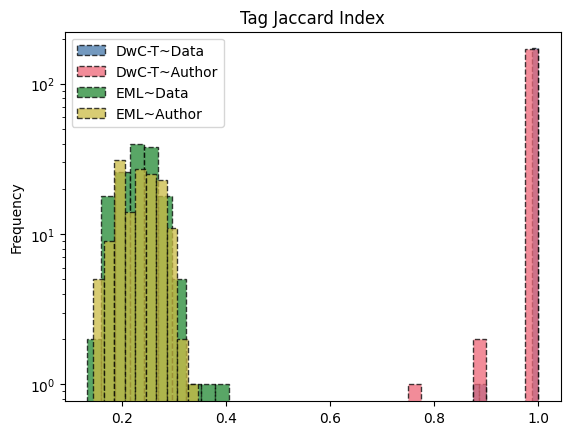

In [62]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_jaccard_index"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Jaccard Index")

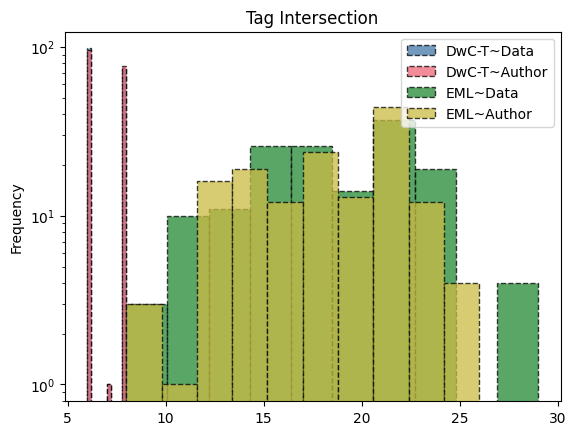

In [63]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_intersection_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Intersection")

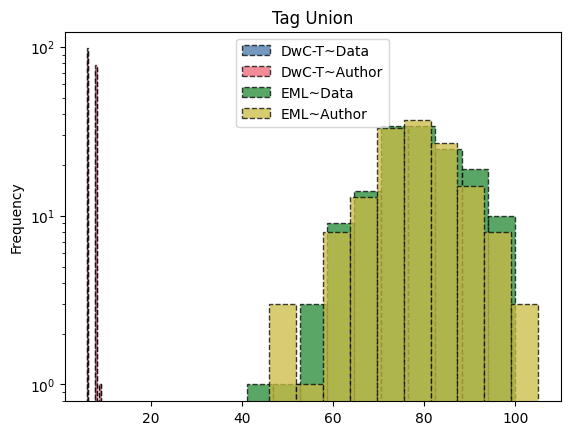

In [64]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.tag_union_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Tag Union")

In [65]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_intersection_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            intersection_size("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.path_union_size"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            union_size("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
    result_groups[g]["cons_vs_gt_tree.path_jaccard_index"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: (
            jaccard_index("path", cons_t, gt_t)
        ) if (
            (cons_t := r["constructed.xml_tree.characteristics"]["value"]) and (gt_t := r["ground_truth.xml_tree.characteristics"]["value"])
        ) else np.nan, 
        axis=1
    )
g, result_groups[g]["cons_vs_gt_tree.path_jaccard_index"]

('EML~Author',
 0      0.058824
 1           NaN
 2      0.111111
 3      0.125000
 4      0.065657
          ...   
 174    0.081081
 175         NaN
 176    0.054645
 177    0.033113
 178    0.077491
 Name: cons_vs_gt_tree.path_jaccard_index, Length: 179, dtype: float64)

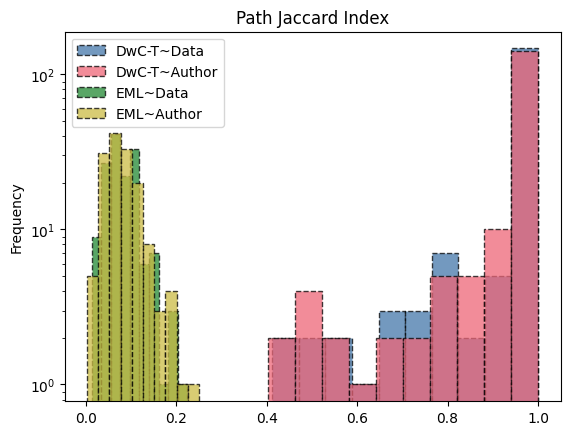

In [66]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_jaccard_index"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Jaccard Index")

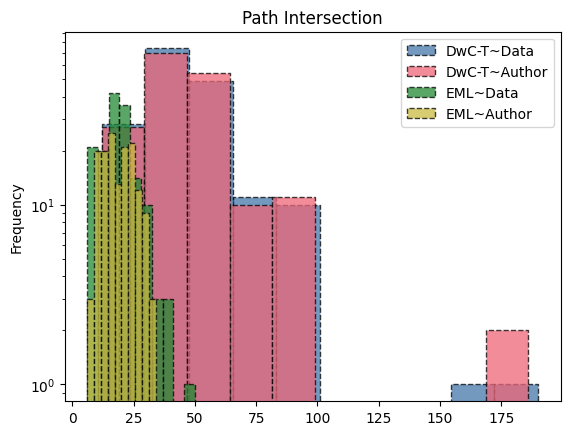

In [67]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_intersection_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Intersection")

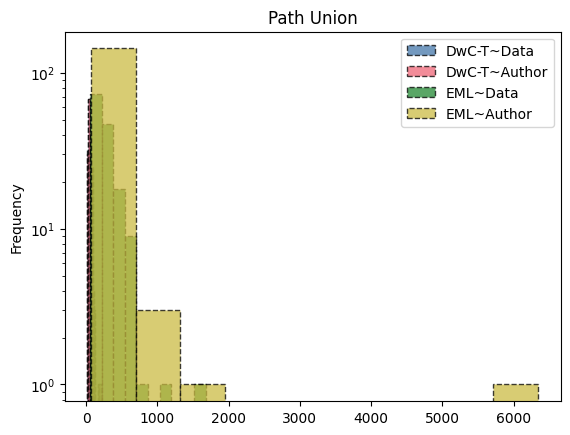

In [68]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.path_union_size"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, label=g, title="Path Union")

In [69]:
for g, rs in result_groups.items():    
    print("----")
    print(g)
    print("Tag JI:\t\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.tag_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.tag_jaccard_index"])))
    print("Path JI:\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.path_jaccard_index"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.path_jaccard_index"])))

----
DwC-T~Data
Tag JI:		 NormaltestResult(statistic=np.float64(315.0412329982547), pvalue=np.float64(3.887455838081462e-69))
(LogN):		 NormaltestResult(statistic=np.float64(315.18451768153244), pvalue=np.float64(3.618691787387586e-69))
Path JI:	 NormaltestResult(statistic=np.float64(131.62678423756907), pvalue=np.float64(2.615814648442218e-29))
(LogN):		 NormaltestResult(statistic=np.float64(152.86861348779337), pvalue=np.float64(6.3826694433743515e-34))
----
DwC-T~Author
Tag JI:		 NormaltestResult(statistic=np.float64(312.92353180132943), pvalue=np.float64(1.1207750141605293e-68))
(LogN):		 NormaltestResult(statistic=np.float64(319.0433757247308), pvalue=np.float64(5.255465839027439e-70))
Path JI:	 NormaltestResult(statistic=np.float64(122.37422463134394), pvalue=np.float64(2.6716204412857325e-27))
(LogN):		 NormaltestResult(statistic=np.float64(140.91977201486793), pvalue=np.float64(2.5099224980133217e-31))
----
EML~Data
Tag JI:		 NormaltestResult(statistic=np.float64(15.73379996063

### Compute Tree Sim (APTED)

In [70]:
@do_on_value
@do_or_error
def xml_to_apted_tree(tree):
    if hasattr(tree, "getroot"):
        return convert_xml_to_apted(tree.getroot())
    return convert_xml_to_apted(tree)

def convert_xml_to_apted(root):
    tag = root.tag
    
    if root.attrib:
        attr_parts = [f"{{key__{k}:{{hidden_value}}}}" for k, _v in sorted(root.attrib.items())]
        node_label = f"{tag}:{':'.join(attr_parts)}"
    else:
        node_label = tag
    
    apted_children = [convert_xml_to_apted(child) for child in root]    
    return apted.helpers.Tree(node_label, *apted_children)

In [71]:
@do_on_value
def apted_tree_size(tree):
    return _apted_tree_size(tree)

def _apted_tree_size(tree):
    return 1 + sum(_apted_tree_size(child) for child in tree.children)

def normalise_apted_edit_distance(raw_distance, tree1, tree2):
    max_dist = _apted_tree_size(tree1) + _apted_tree_size(tree2)
    return raw_distance / max_dist if max_dist > 0 else 0

In [72]:
def get_error_breakdown(apted_edit_mapping):
    breakdown = {
        "deletions": [],    # In Tree 1, but not in Tree 2
        "insertions": [],   # In Tree 2, but not in Tree 1
        "renames": [],      # In both, but labels/attributes differ
        "matches": []       # Identical nodes
    }
    
    for node1, node2 in apted_edit_mapping:
        if node1 is None:
            # Node exists only in generated (Tree 2) -> Hallucination
            breakdown["insertions"].append(node2.name)
        elif node2 is None:
            # Node exists only in ground truth (Tree 1) -> Omission
            breakdown["deletions"].append(node1.name)
        else:
            # Both exist; check if the label (tag + attributes) is the same
            if node1.name != node2.name:
                breakdown["renames"].append((node1.name, node2.name))
            else:
                breakdown["matches"].append(node1.name)

    counts = {f"{key}_count": len(vals) for key, vals in breakdown.items()}
    total = sum(v for _, v in counts.items())
    return {
        **breakdown, 
        **counts,
        "total": total,
        "replacements_count": total - counts["matches_count"],
    }

In [73]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.apted_format"] = with_ok_constructed_trees(rs)["constructed.xml_tree"].apply(xml_to_apted_tree)
    result_groups[g]["ground_truth.xml_tree.apted_format"] = with_ok_constructed_trees(rs)["ground_truth.xml_tree"].apply(xml_to_apted_tree)

In [74]:
(
    with_ok_constructed_trees(rs)["ground_truth.xml_tree.apted_format"].apply(apted_tree_size), 
    with_ok_constructed_trees(rs)["ground_truth.xml_tree.characteristics"].apply(lambda x: x["value"]["size"])
)

(0      511
 2      176
 3       85
 4      366
 5      201
       ... 
 171    156
 174     88
 176    147
 177    592
 178    251
 Name: ground_truth.xml_tree.apted_format, Length: 148, dtype: int64,
 0      511
 2      176
 3       85
 4      366
 5      201
       ... 
 171    156
 174     88
 176    147
 177    592
 178    251
 Name: ground_truth.xml_tree.characteristics, Length: 148, dtype: int64)

In [75]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"] = with_ok_constructed_trees(rs).apply(
        lambda x: apted.APTED(x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_distance()
    )

CPU times: user 17.2 s, sys: 573 ms, total: 17.8 s
Wall time: 17.8 s


In [76]:
result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"]

0      479.0
1        NaN
2      164.0
3       74.0
4      343.0
       ...  
174     76.0
175      NaN
176    134.0
177    569.0
178    232.0
Name: cons_vs_gt_tree.apted_tree_edit_distance, Length: 179, dtype: float64

In [77]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.normalised"] = with_ok_constructed_trees(rs).apply(
        lambda x: normalise_apted_edit_distance(x["cons_vs_gt_tree.apted_tree_edit_distance"], x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    )
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"] = 1 - with_ok_constructed_trees(result_groups[g])["cons_vs_gt_tree.apted_tree_edit_distance.normalised"]

CPU times: user 27.9 ms, sys: 3.08 ms, total: 30.9 ms
Wall time: 28.9 ms


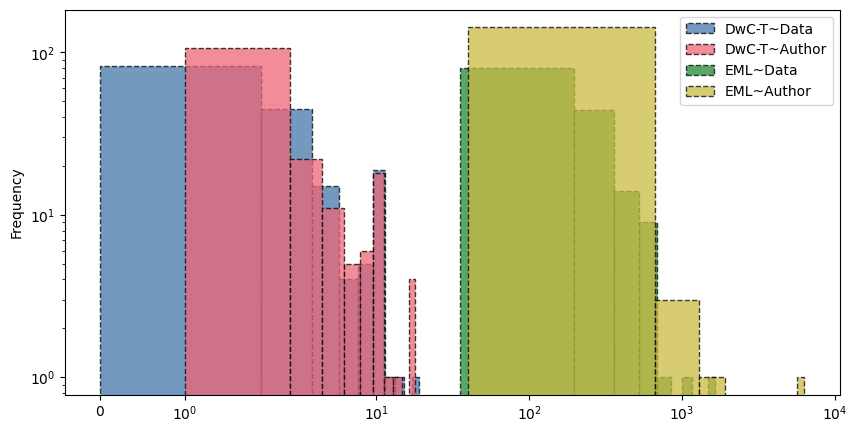

In [78]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_xscale("symlog")
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g)

plt.show()

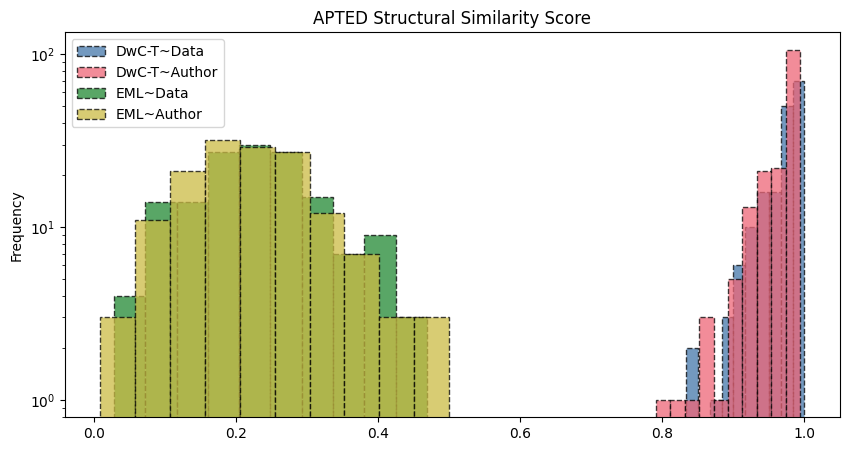

In [79]:
fig, ax = plt.subplots(figsize=(10,5))

ax.set_title("APTED Structural Similarity Score")
# ax.set_xscale("symlog")
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"].plot.hist(alpha=0.75, ls="--", lw=1, edgecolor="black", legend=True, log=True, ax=ax, label=g)

plt.show()

In [80]:
for g, rs in result_groups.items():    
    print("----")
    print(g)
    print("APTED:\t\t", stats.normaltest(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"]))
    print("(LogN):\t\t", stats.normaltest(np.log(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_distance.sim_score"])))

----
DwC-T~Data
APTED:		 NormaltestResult(statistic=np.float64(77.66299240596564), pvalue=np.float64(1.3667701175093959e-17))
(LogN):		 NormaltestResult(statistic=np.float64(84.61479710069335), pvalue=np.float64(4.227954120243065e-19))
----
DwC-T~Author
APTED:		 NormaltestResult(statistic=np.float64(101.9286818901659), pvalue=np.float64(7.353057357785612e-23))
(LogN):		 NormaltestResult(statistic=np.float64(112.01230595060193), pvalue=np.float64(4.751566482887408e-25))
----
EML~Data
APTED:		 NormaltestResult(statistic=np.float64(2.691908376516904), pvalue=np.float64(0.260291222499635))
(LogN):		 NormaltestResult(statistic=np.float64(32.32784465636306), pvalue=np.float64(9.552075070614842e-08))
----
EML~Author
APTED:		 NormaltestResult(statistic=np.float64(3.5236131943040427), pvalue=np.float64(0.1717343286524855))
(LogN):		 NormaltestResult(statistic=np.float64(86.84843494684779), pvalue=np.float64(1.3838912720653072e-19))


In [81]:
%%time
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping"] = with_ok_constructed_trees(rs).apply(
        lambda x: apted.APTED(x["constructed.xml_tree.apted_format"]["value"], x["ground_truth.xml_tree.apted_format"]["value"]), 
        axis=1,
    ).apply(
        lambda a: a.compute_edit_mapping()
    )

CPU times: user 18.4 s, sys: 517 ms, total: 18.9 s
Wall time: 19 s


In [118]:
for g, rs in result_groups.items():
    result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"] = with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_mapping"].apply(get_error_breakdown)
    print(g, result_groups[g]["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"])
    result_groups[g].to_csv(f"{g.replace('~','-')}.edit-distance.csv")

DwC-T~Data 0      {'deletions': ['{http://rs.tdwg.org/dwc/text/}...
1      {'deletions': [], 'insertions': [], 'renames':...
2      {'deletions': [], 'insertions': [], 'renames':...
3      {'deletions': [], 'insertions': [], 'renames':...
4      {'deletions': ['{http://rs.tdwg.org/dwc/text/}...
                             ...                        
174    {'deletions': [], 'insertions': [], 'renames':...
175    {'deletions': [], 'insertions': [], 'renames':...
176    {'deletions': [], 'insertions': [], 'renames':...
177    {'deletions': [], 'insertions': [], 'renames':...
178    {'deletions': [], 'insertions': [], 'renames':...
Name: cons_vs_gt_tree.apted_tree_edit_mapping_breakdown, Length: 179, dtype: object
DwC-T~Author 0      {'deletions': ['{http://rs.tdwg.org/dwc/text/}...
1      {'deletions': [], 'insertions': [], 'renames':...
2      {'deletions': [], 'insertions': [], 'renames':...
3      {'deletions': [], 'insertions': [], 'renames':...
4      {'deletions': ['{http://rs.tdw

In [128]:
pd.Series(itlx.chain.from_iterable([b["deletions"] for b in result_groups["DwC-T~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}                                                                                                                                      21
{http://rs.tdwg.org/dwc/text/}files                                                                                                                                                                                             21
{http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}                                                                                                                                                                20
{http://rs.tdwg.org/dwc/text/}location                                                                                                                                                                                          19
{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedB

In [129]:
pd.Series(itlx.chain.from_iterable([b["insertions"] for b in result_groups["DwC-T~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

{http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}                                                                                                                                                                              36
{http://rs.tdwg.org/dwc/text/}extension:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__linesTerminatedBy:{hidden_value}}:{key__rowType:{hidden_value}}    28
{http://rs.tdwg.org/dwc/text/}files                                                                                                                                                                                                                                     21
{http://rs.tdwg.org/dwc/text/}coreid:{key__index:{hidden_value}}                                                                                                                                       

In [130]:
pd.Series(itlx.chain.from_iterable([b["renames"] for b in result_groups["DwC-T~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

({http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__rowType:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}core:{key__encoding:{hidden_value}}:{key__fieldsEnclosedBy:{hidden_value}}:{key__fieldsTerminatedBy:{hidden_value}}:{key__ignoreHeaderLines:{hidden_value}}:{key__linesTerminatedBy:{hidden_value}}:{key__rowType:{hidden_value}})                                     109
({http://rs.tdwg.org/dwc/text/}field:{key__index:{hidden_value}}:{key__term:{hidden_value}}, {http://rs.tdwg.org/dwc/text/}field:{key__delimitedBy:{hidden_value}}:{key__index:{hidden_value}}:{key__term:{hidden_value}})                                                                                                                                                                                                                                                                           

In [131]:
pd.Series(itlx.chain.from_iterable([b["insertions"] for b in result_groups["EML~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

taxonRankValue                                        2433
taxonomicClassification                               2401
taxonRankName                                         2295
givenName                                             1696
surName                                               1590
                                                      ... 
relatedProject:{key__id:{hidden_value}}                  2
jgtiUnits:{key__uncertaintyMeasure:{hidden_value}}       1
itemizedlist                                             1
award                                                    1
awardNumber                                              1
Name: count, Length: 123, dtype: int64

In [132]:
pd.Series(itlx.chain.from_iterable([b["deletions"] for b in result_groups["EML~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

project                                                                                    130
methods                                                                                     77
maintenanceUpdateFrequency                                                                  63
instrumentation                                                                             61
descriptor:{key__citableClassificationSystem:{hidden_value}}:{key__name:{hidden_value}}     56
                                                                                          ... 
geographicScope                                                                              1
{https://example.org/eml/extensions/1.0}customExtensions                                     1
customExtensions                                                                             1
accessionDate                                                                                1
provenanceNote                                    

In [133]:
pd.Series(itlx.chain.from_iterable([b["renames"] for b in result_groups["EML~Data"][
    "cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"
].tolist() if isinstance(b, dict)])).value_counts()

(para, givenName)                      167
(description, individualName)          152
(title, alternateIdentifier)           146
(funding, abstract)                     70
(instrumentation, organizationName)     69
                                      ... 
(taxonomicScope, citation)               1
(internalIdentifiers, bibliography)      1
(institutionCode, citation)              1
(geographicDatum, citation)              1
(contextNote, citation)                  1
Name: count, Length: 601, dtype: int64

In [83]:
tree_edit_breakdown_groups = {}

for g, rs in result_groups.items():
    tree_edit_breakdown_groups[g] = pd.DataFrame.from_records(with_ok_constructed_trees(rs)["cons_vs_gt_tree.apted_tree_edit_mapping_breakdown"])
    tree_edit_breakdown_groups[g]["case_id"] = with_ok_constructed_trees(rs)["case_id"]
    
    print(g)
    display(tree_edit_breakdown_groups[g].describe())

DwC-T~Data


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.712644,0.816092,1.701149,46.735632,49.965517,3.229885,89.130178
std,1.692609,1.887156,1.471226,22.381846,23.894977,3.506233,53.073575
min,0.000000,0.000000,0.000000,11.000000,12.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,34.000000,1.000000,42.000000
50%,0.000000,0.000000,1.000000,43.000000,45.500000,2.000000,87.000000
75%,0.000000,0.000000,2.000000,56.000000,62.000000,4.000000,136.000000
max,7.000000,12.000000,9.000000,188.000000,202.000000,19.000000,178.000000


DwC-T~Author


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.873563,1.034483,1.718391,46.614943,50.241379,3.626437,89.124260
std,1.922213,2.293233,1.400250,21.958342,23.743312,3.884695,52.258651
min,0.000000,0.000000,0.000000,11.000000,12.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,35.000000,1.000000,44.000000
50%,0.000000,0.000000,1.000000,43.000000,47.000000,2.000000,87.000000
75%,0.000000,1.000000,2.000000,56.000000,62.000000,5.000000,135.000000
max,9.000000,16.000000,9.000000,185.000000,202.000000,18.000000,178.000000


EML~Data


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,129.000000
mean,5.933333,223.613333,16.626667,19.900000,266.073333,246.173333,89.612403
std,3.490479,196.237248,9.115623,7.429986,196.597879,193.880948,56.728287
min,2.000000,10.000000,2.000000,8.000000,43.000000,35.000000,0.000000
25%,3.000000,108.000000,10.250000,14.000000,145.000000,131.000000,36.000000
50%,5.000000,168.500000,17.000000,17.000000,209.000000,187.500000,101.000000
75%,8.000000,284.000000,24.000000,26.000000,331.250000,301.750000,142.000000
max,21.000000,1637.000000,37.000000,51.000000,1671.000000,1650.000000,178.000000


EML~Author


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,123.000000
mean,5.141892,274.790541,15.229730,19.722973,314.885135,295.162162,95.268293
std,2.955475,540.316816,8.706159,6.051728,540.173473,539.508646,55.125650
min,2.000000,4.000000,2.000000,6.000000,46.000000,40.000000,0.000000
25%,3.000000,109.500000,8.000000,15.000000,148.750000,130.000000,44.000000
50%,4.000000,177.500000,16.000000,18.000000,212.500000,192.000000,110.000000
75%,7.000000,287.500000,22.000000,25.000000,333.000000,304.500000,143.500000
max,16.000000,6295.000000,38.000000,37.000000,6329.000000,6311.000000,178.000000


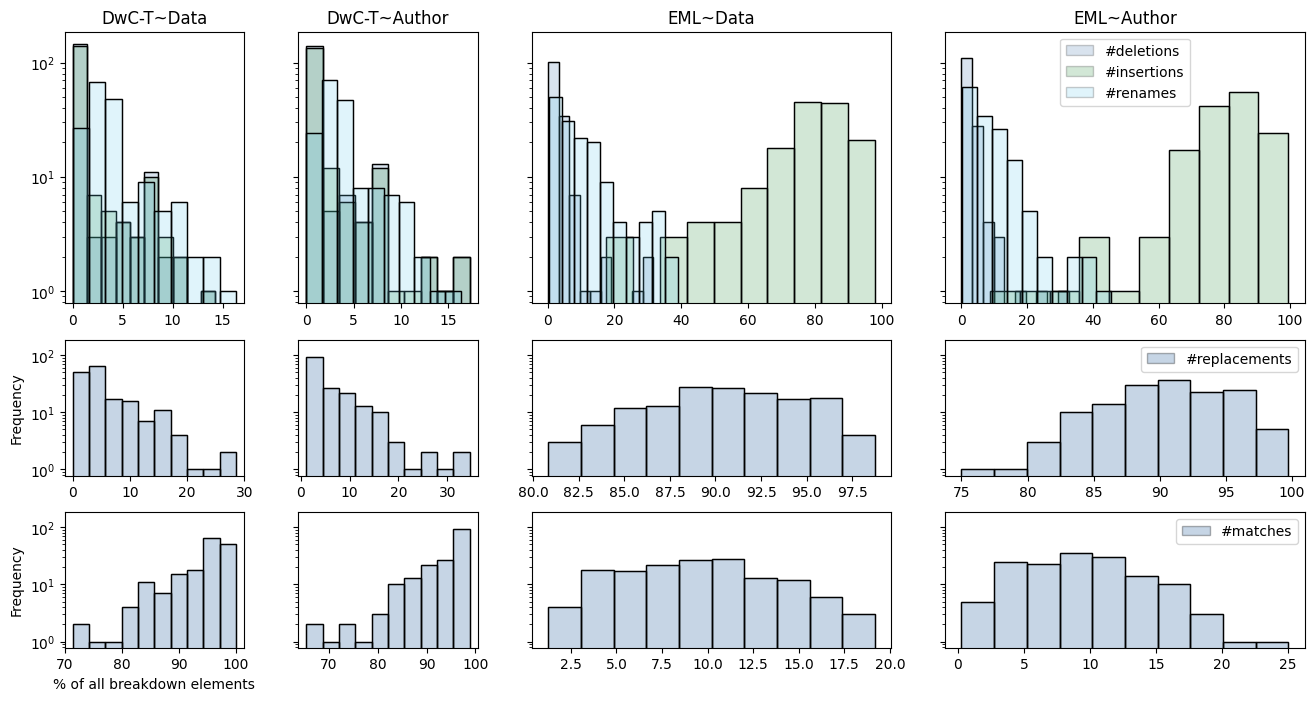

In [84]:
fig, axs = plt.subplots(3, len(tree_edit_breakdown_groups.keys()), figsize=(16,8), sharey=True, height_ratios=(2,1,1), width_ratios=(1,1,2,2))

matches_c = "matches_count"
replacements_c = "replacements_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    # matches_c
]

for i, (ax_t, (g, rs)) in enumerate(zip(axs[0], tree_edit_breakdown_groups.items())):
    # ax_t.set_xscale("symlog")
    ax_t.set_title(g)
    for j, (c, ls) in enumerate(zip(columns, ["--", "-.", ":"])):
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, alpha=0.2, edgecolor="k", log=True, ax=ax_t, label=("#" + c.split("_")[0]))
        ((rs[c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_t)
    ax_t.legend() if i == 3 else ...
    ax_t.set_ylabel("")

for i, (ax_m, (g, rs)) in enumerate(zip(axs[1], tree_edit_breakdown_groups.items())):
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_m, label="#" + replacements_c.split("_")[0])
    ((rs[replacements_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_m)
    ax_m.legend() if i == 3 else ...

for i, (ax_b, (g, rs)) in enumerate(zip(axs[2], tree_edit_breakdown_groups.items())):
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(alpha=0.3, ls="-", lw=1, edgecolor="k", log=True, ax=ax_b, label="#" + matches_c.split("_")[0])
    ((rs[matches_c] / rs["total"]) * 100).plot.hist(ls="-", lw=1, facecolor="#ffffff00", edgecolor="k", log=True, ax=ax_b)
    ax_b.set_xlabel("% of all breakdown elements") if i == 0 else ...
    ax_b.legend() if i == 3 else ...

plt.show()

In [85]:
matches_c = "matches_count"
columns = [
    "deletions_count", 
    "insertions_count", 
    "renames_count", 
    matches_c
]

for c in columns:
    for g, rs in tree_edit_breakdown_groups.items():    
        print(f"---- {c} ----")
        print(g)
        print(f"{c}:\t", stats.normaltest(rs[c]))
        print("(LogN1P):\t", stats.normaltest(np.log1p(rs[c])))

---- deletions_count ----
DwC-T~Data
deletions_count:	 NormaltestResult(statistic=np.float64(79.14247900153), pvalue=np.float64(6.522724606800856e-18))
(LogN1P):	 NormaltestResult(statistic=np.float64(67.27282061684934), pvalue=np.float64(2.465429635150809e-15))
---- deletions_count ----
DwC-T~Author
deletions_count:	 NormaltestResult(statistic=np.float64(94.01209849147097), pvalue=np.float64(3.850633603664285e-21))
(LogN1P):	 NormaltestResult(statistic=np.float64(53.15807092682606), pvalue=np.float64(2.863331057521004e-12))
---- deletions_count ----
EML~Data
deletions_count:	 NormaltestResult(statistic=np.float64(52.52560233300562), pvalue=np.float64(3.928351803244184e-12))
(LogN1P):	 NormaltestResult(statistic=np.float64(3.1513306989673864), pvalue=np.float64(0.2068698661227753))
---- deletions_count ----
EML~Author
deletions_count:	 NormaltestResult(statistic=np.float64(31.62829087711292), pvalue=np.float64(1.3552015821782305e-07))
(LogN1P):	 NormaltestResult(statistic=np.float64(10

### Reporting Pairwise Structural Similiarity

#### Top-K Common Tags and Paths

In [86]:
all_tags_groups = {}

for g in cons_node_info_groups.keys():
    all_tags = sorted(list(set.union(
        set(cons_node_info_groups[g]["tag"].apply(str).unique().tolist()),
        set(gt_node_info_groups[g]["tag"].apply(str).unique().tolist()),
    )))
    all_tags_groups[g] = {
        "values": all_tags, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [87]:
all_paths_groups = {}

for g in cons_node_info_groups.keys():
    all_paths = sorted(list(set.union(
        set(cons_node_info_groups[g]["path"].apply(str).unique().tolist()),
        set(gt_node_info_groups[g]["path"].apply(str).unique().tolist()),
    )))
    all_paths_groups[g] = {
        "values": all_paths, 
        "mapper_key_to_idx": {t: i for i, t in enumerate(all_tags)},
        "mapper_idx_to_key": {i: t for i, t in enumerate(all_tags)},
    }

In [88]:
# inspect EML intersections
cons_node_info_groups["EML~Data"].merge(gt_node_info_groups["EML~Data"], on=["path", "case_id"], suffixes=["__cons", "__gt"])

,case_id,tag__cons,depth__cons,degree__cons,is_leaf__cons,attributes__cons,attributes_count__cons,has_attributes__cons,text__cons,has_text__cons,path,tag__gt,depth__gt,degree__gt,is_leaf__gt,attributes__gt,attributes_count__gt,has_attributes__gt,text__gt,has_text__gt
0,0,{https://eml.ecoinformatics.org/eml-2.2.0}eml,0,2,False,"{""packageId"": ""not-derived-000"", ""system"": ""kn...",3,True,\n,False,.,{https://eml.ecoinformatics.org/eml-2.2.0}eml,0,2,False,"{""{http://www.w3.org/2001/XMLSchema-instance}s...",5,True,\n,False
1,0,dataset,1,5,False,{},0,False,\n,False,dataset,dataset,1,26,False,{},0,False,\n,False
2,0,title,2,0,True,{},0,False,not-derived-001,True,dataset/title,title,2,0,True,"{""{http://www.w3.org/XML/1998/namespace}lang"":...",1,True,Coastal Grassland Vegetation Records from São ...,True
3,0,methods,2,2,False,{},0,False,\n,False,dataset/methods,methods,2,3,False,{},0,False,\n,False
4,0,methodStep,3,2,False,{},0,False,\n,False,dataset/methods/methodStep,methodStep,3,1,False,{},0,False,\n,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2839,98,description,3,1,False,{},0,False,\n,False,dataset/maintenance/description,description,3,1,False,{},0,False,\n,False
2840,98,para,4,0,True,{},0,False,Dataset status: archived/actively managed obse...,True,dataset/maintenance/description/para,para,4,0,True,{},0,False,NaN,False
2841,98,maintenanceUpdateFrequency,3,0,True,{},0,False,irregular,True,dataset/maintenance/maintenanceUpdateFrequency,maintenanceUpdateFrequency,3,0,True,{},0,False,annually,True
2842,98,additionalMetadata,1,2,False,{},0,False,\n,False,additionalMetadata,additionalMetadata,1,1,False,{},0,False,\n,False


                                                    count
path                                                     
additionalMetadata/metadata/customContext/notes         2
additionalMetadata/metadata/customMetadata/proj...      1
additionalMetadata/metadata/customMetadata/rela...      1
dataset/project/studyAreaDescription/descriptor...      1
additionalMetadata/metadata/customMetadata             48
...                                                   ...
additionalMetadata/metadata/projectContext/nota...      1
additionalMetadata/metadata/customMetadata/temp...      2
additionalMetadata/metadata/projectContext/notes        1
additionalMetadata/metadata/customMetadata/prov...      1
additionalMetadata/metadata/customMetadata/taxo...      3

[590 rows x 1 columns]                                                     count
path                                                     
dataset/creator[3]/individualName/salutation            1
dataset/coverage/taxonomicCoverage/taxonomicCla.

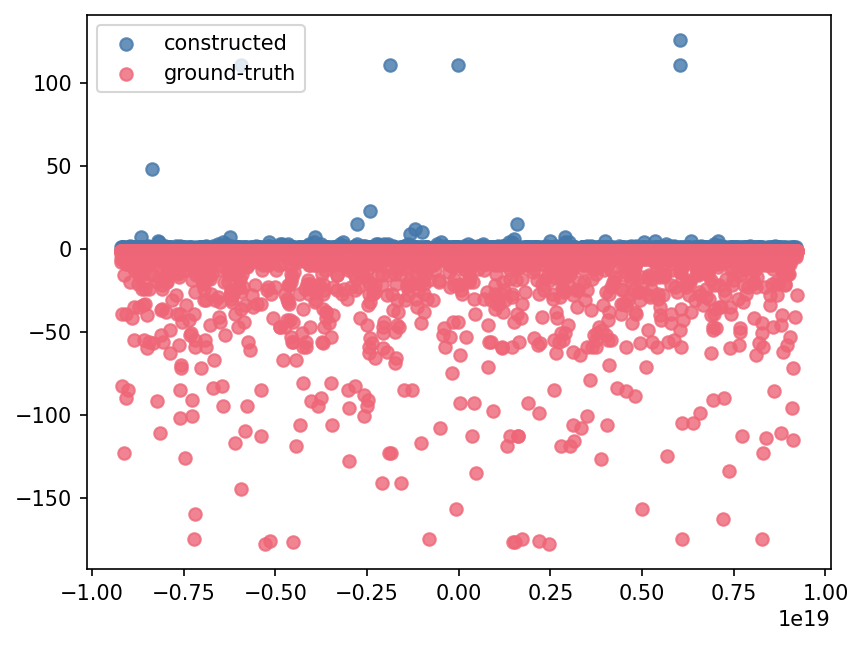

,count
path,
dataset/methods/methodStep/instrumentation,126
dataset/project/studyAreaDescription/descriptor[2],111
dataset/project/studyAreaDescription/descriptor[1]/descriptorValue,111
dataset/project/studyAreaDescription/descriptor[2]/descriptorValue,111
dataset/project/studyAreaDescription/descriptor[1],111
additionalMetadata/metadata/customMetadata,48
dataset/methods/methodStep[1]/instrumentation,23
dataset/project/studyAreaDescription/descriptor[3],15
dataset/project/studyAreaDescription/descriptor[3]/descriptorValue,15


,count
path,
dataset/pubDate,178
dataset/intellectualRights/para/ulink,178
dataset/intellectualRights/para/ulink/citetitle,177
additionalMetadata/metadata/gbif,177
dataset/language,177
additionalMetadata/metadata/gbif/dateStamp,176
additionalMetadata/metadata/gbif/hierarchyLevel,176
dataset/coverage/geographicCoverage/boundingCoordinates/westBoundingCoordinate,175
dataset/coverage/geographicCoverage/boundingCoordinates,175


In [89]:
# inspect EML differences (Data)
cons_path_vl_counts = pd.DataFrame(cons_node_info_groups["EML~Data"]["path"].value_counts())
gt_path_vl_counts = pd.DataFrame(gt_node_info_groups["EML~Data"]["path"].value_counts())

cons_not_gt = list(
    set.difference(set(cons_path_vl_counts.index), set(gt_path_vl_counts.index))
)
gt_not_const = list(
    set.difference(set(gt_path_vl_counts.index), set(cons_path_vl_counts.index))
)

cons_not_gt_df = cons_path_vl_counts.loc[cons_not_gt]
gt_not_cons_df = gt_path_vl_counts.loc[gt_not_const]

print(cons_not_gt_df, gt_not_cons_df)

fig,ax = plt.subplots(dpi=150)


ax.scatter(
    list(map(hash, cons_not_gt_df.index)), 
    cons_not_gt_df["count"],
    alpha=0.8,
    label="constructed"
)
ax.scatter(
    list(map(hash, gt_not_cons_df.index)), 
    gt_not_cons_df["count"] * -1,
    alpha=0.8,
    label="ground-truth"
)

ax.legend()
plt.show()

display(cons_not_gt_df.nlargest(20, columns=["count"]))
display(gt_not_cons_df.nlargest(20, columns=["count"]))

                                                    count
path                                                     
dataset/additionalMetadata/metadata/provenance/...      1
additionalMetadata/metadata/{https://eml.ecoinf...      1
additionalMetadata/metadata/customMetadata/proj...      1
additionalMetadata/metadata/customProvenance/no...      1
additionalMetadata/metadata/customMetadata             40
...                                                   ...
additionalMetadata/metadata/customProvenance/re...      1
additionalMetadata/metadata/customExtensions/re...      1
additionalMetadata/metadata/customMetadata/meth...      1
additionalMetadata/metadata/customMetadata/taxo...      1
additionalMetadata/metadata/customMetadata/cont...      1

[474 rows x 1 columns]                                                     count
path                                                     
dataset/creator[3]/individualName/salutation            1
dataset/coverage/taxonomicCoverage/taxonomicCla.

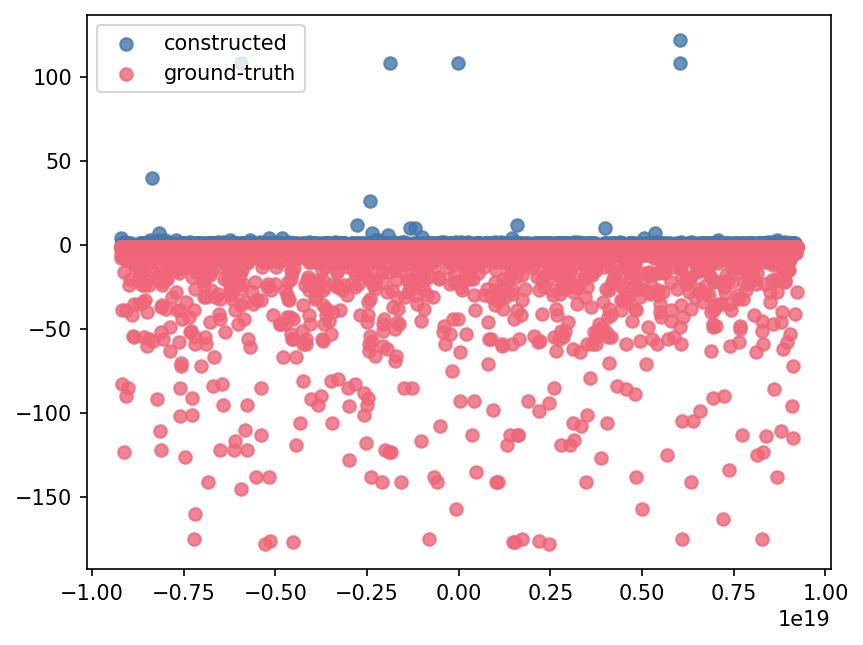

,count
path,
dataset/methods/methodStep/instrumentation,122
dataset/project/studyAreaDescription/descriptor[2],108
dataset/project/studyAreaDescription/descriptor[1]/descriptorValue,108
dataset/project/studyAreaDescription/descriptor[2]/descriptorValue,108
dataset/project/studyAreaDescription/descriptor[1],108
additionalMetadata/metadata/customMetadata,40
dataset/methods/methodStep[1]/instrumentation,26
dataset/project/studyAreaDescription/descriptor[3],12
dataset/project/studyAreaDescription/descriptor[3]/descriptorValue,12


,count
path,
dataset/pubDate,178
dataset/intellectualRights/para/ulink,178
dataset/intellectualRights/para/ulink/citetitle,177
additionalMetadata/metadata/gbif,177
dataset/language,177
additionalMetadata/metadata/gbif/dateStamp,176
additionalMetadata/metadata/gbif/hierarchyLevel,176
dataset/coverage/geographicCoverage/boundingCoordinates/westBoundingCoordinate,175
dataset/coverage/geographicCoverage/boundingCoordinates,175


In [90]:
# inspect EML differences (Author)
cons_path_vl_counts = pd.DataFrame(cons_node_info_groups["EML~Author"]["path"].value_counts())
gt_path_vl_counts = pd.DataFrame(gt_node_info_groups["EML~Author"]["path"].value_counts())

cons_not_gt = list(
    set.difference(set(cons_path_vl_counts.index), set(gt_path_vl_counts.index))
)
gt_not_const = list(
    set.difference(set(gt_path_vl_counts.index), set(cons_path_vl_counts.index))
)

cons_not_gt_df = cons_path_vl_counts.loc[cons_not_gt]
gt_not_cons_df = gt_path_vl_counts.loc[gt_not_const]

print(cons_not_gt_df, gt_not_cons_df)

fig,ax = plt.subplots(dpi=150)


ax.scatter(
    list(map(hash, cons_not_gt_df.index)), 
    cons_not_gt_df["count"],
    alpha=0.8,
    label="constructed"
)
ax.scatter(
    list(map(hash, gt_not_cons_df.index)), 
    gt_not_cons_df["count"] * -1,
    alpha=0.8,
    label="ground-truth"
)

ax.legend()
plt.show()

display(cons_not_gt_df.nlargest(20, columns=["count"]))
display(gt_not_cons_df.nlargest(20, columns=["count"]))

In [91]:
TOP_K = 10

cons_top_k=tag
field        7310
files         267
location      267
archive       174
core          174
id            174
extension      93
coreid         93
Name: count, dtype: int64
gt_top_k=tag
field           7530
files            279
location         279
archive          179
core             179
id               179
extension        100
coreid            99
<!-- ... -->       2
Name: count, dtype: int64
cons_top_k=tag
field        7308
files         270
location      270
archive       174
core          174
id            174
extension      96
coreid         96
Name: count, dtype: int64
gt_top_k=tag
field           7530
files            279
location         279
archive          179
core             179
id               179
extension        100
coreid            99
<!-- ... -->       2
Name: count, dtype: int64
cons_top_k=tag
para               697
description        483
individualName     388
surName            388
title              301
descriptor         278
descriptorValue    27

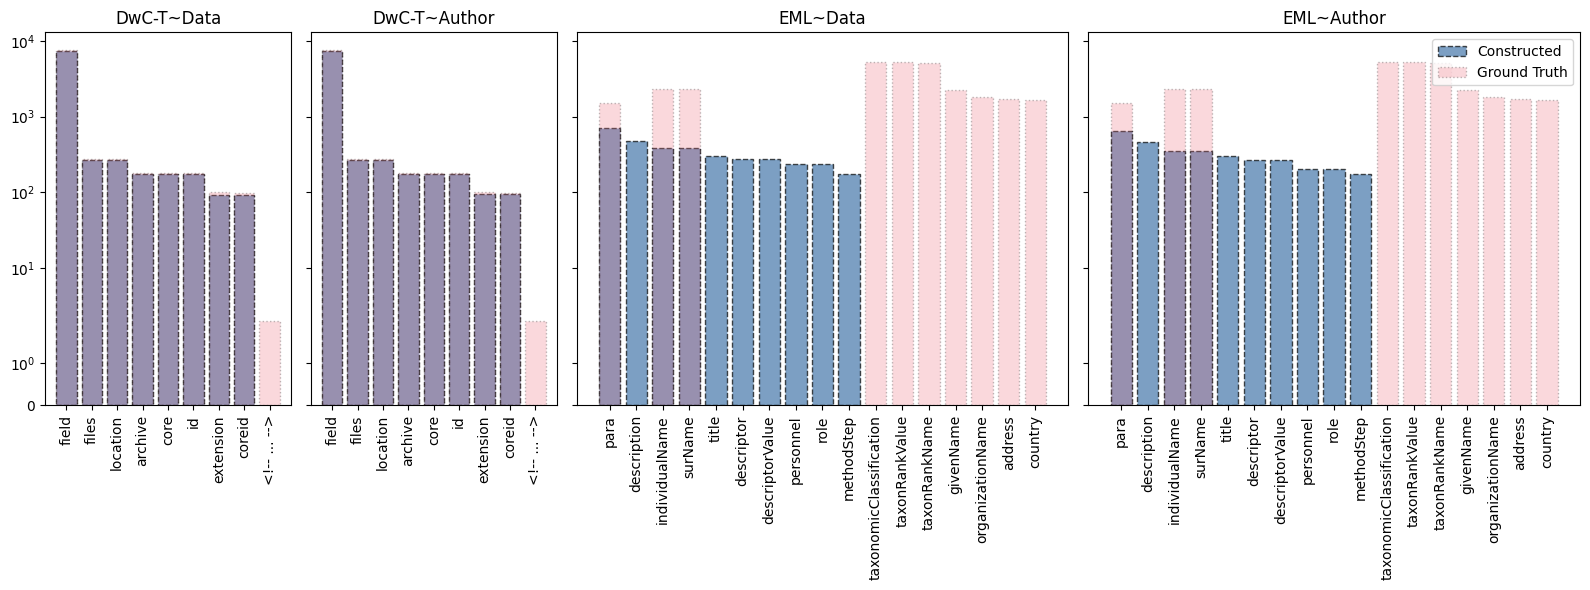

In [92]:
fig,axs = plt.subplots(1, 4, figsize=(16,6), sharey=True, width_ratios=(1,1,2,2))

for i, (ax, (g, cons_rs), (_, gt_rs)) in enumerate(zip(axs, cons_node_info_groups.items(), gt_node_info_groups.items())):
    cons_top_k = (
        cons_rs["tag"]
            # .apply(lambda t: all_tags_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else st.split("}")[-1])
            .value_counts().nlargest(TOP_K)
    )
    gt_top_k = (
        gt_rs["tag"]
            # .apply(lambda t: all_tags_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else st.split("}")[-1])
            .value_counts().nlargest(TOP_K)
    )

    print(f"{cons_top_k=}")
    print(f"{gt_top_k=}")

    ax.set_title(g)
    ax.set_yscale("symlog")
    ax.tick_params("x", rotation=90)
    
    ax.bar(cons_top_k.index, cons_top_k, alpha=0.7, label="Constructed", ls="--", lw=1, edgecolor="black")
    ax.bar(gt_top_k.index, gt_top_k, alpha=0.25, label="Ground Truth", ls=":", lw=1, edgecolor="black")
    
    ax.legend(loc="upper right") if i == 3 else ...
    
plt.tight_layout()
plt.show()

cons_top_k=path
core                                               174
core $\rightarrow$ files                           174
core $\rightarrow$ files $\rightarrow$ location    174
core $\rightarrow$ id                              174
core $\rightarrow$ field[1]                        174
core $\rightarrow$ field[2]                        174
core $\rightarrow$ field[3]                        174
core $\rightarrow$ field[4]                        174
core $\rightarrow$ field[5]                        174
core $\rightarrow$ field[6]                        174
Name: count, dtype: int64
gt_top_k=path
core                                               179
core $\rightarrow$ files                           179
core $\rightarrow$ files $\rightarrow$ location    179
core $\rightarrow$ id                              179
core $\rightarrow$ field[1]                        179
core $\rightarrow$ field[2]                        179
core $\rightarrow$ field[3]                        179
core $\ri

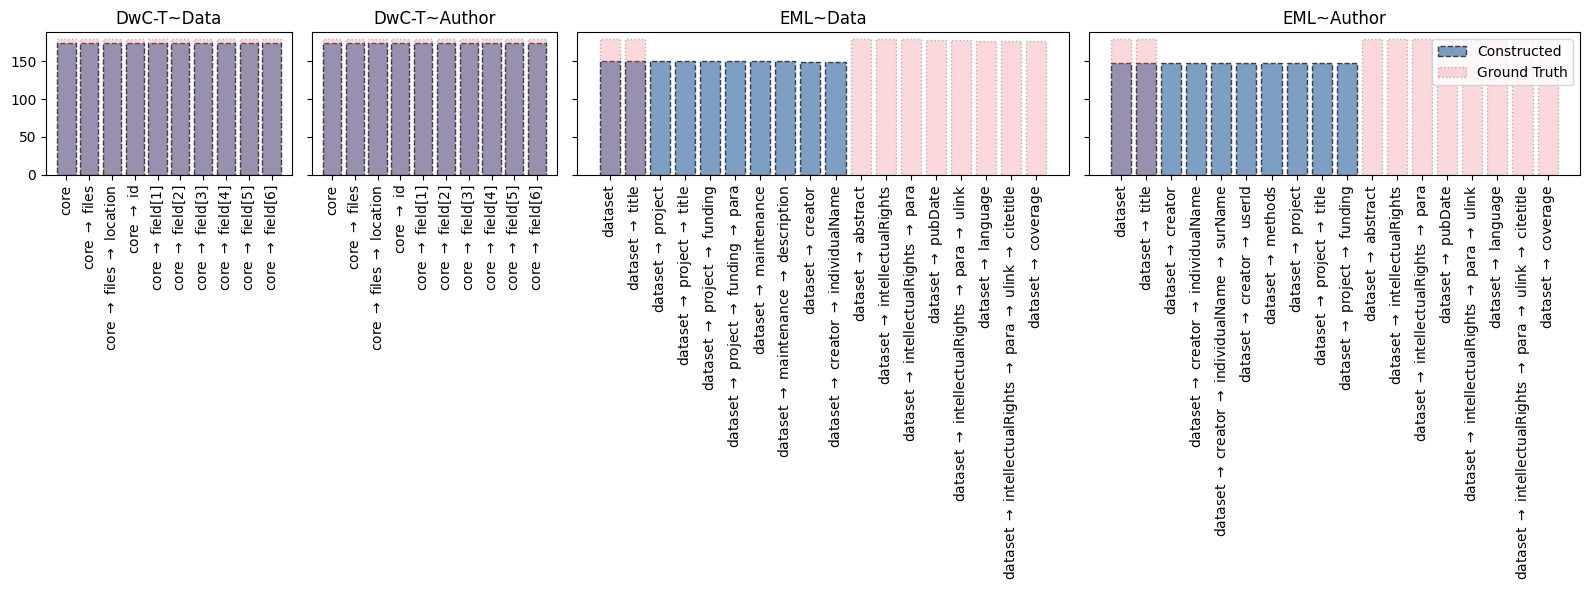

In [93]:
fig,axs = plt.subplots(1, 4, figsize=(16,6), sharey=True, width_ratios=(1,1,2,2))

for i, (ax, (g, cons_rs), (_, gt_rs)) in enumerate(zip(axs, cons_node_info_groups.items(), gt_node_info_groups.items())):
    cons_top_k = (
        cons_rs[cons_rs["path"] != "."]["path"]
            # .apply(lambda t: all_paths_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else " $\\rightarrow$ ".join(re.sub(r"\{[^\{]+\}", "", st).split("/")))
            .value_counts().nlargest(TOP_K)
    )
    gt_top_k = (
        gt_rs[gt_rs["path"] != "."]["path"]
            # .apply(lambda t: all_paths_groups[g]["mapper_key_to_idx"][str(t)])
            .apply(lambda t: "<!-- ... -->" if (st:=str(t)) and "Comment" in st else " $\\rightarrow$ ".join(re.sub(r"\{[^\{]+\}", "", st).split("/")))
            .value_counts().nlargest(TOP_K)
    )

    print(f"{cons_top_k=}")
    print(f"{gt_top_k=}")

    ax.set_title(g)
    ax.tick_params("x", rotation=90)
    
    ax.bar(cons_top_k.index, cons_top_k, alpha=0.7, label="Constructed", ls="--", lw=1, edgecolor="black")
    ax.bar(gt_top_k.index, gt_top_k, alpha=0.25, label="Ground Truth", ls=":", lw=1, edgecolor="black")
    
    ax.legend(loc="upper right") if i == 3 else ...
    
plt.tight_layout()
plt.show()

#### Descriptive Stats

In [94]:
print("Constructed VS Ground Truth: Tree Structural Similarity\n")

for g, rs in result_groups.items():
    print(f"--- {g} ----")
    display(result_groups[g][["cons_vs_gt_tree.apted_tree_edit_distance.sim_score", "cons_vs_gt_tree.tag_jaccard_index", "cons_vs_gt_tree.path_jaccard_index"]].describe())

Constructed VS Ground Truth: Tree Structural Similarity

--- DwC-T~Data ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,174.000000,174.000000,174.000000
mean,0.968317,0.998643,0.957505
std,0.029243,0.012642,0.112452
min,0.833333,0.875000,0.412371
25%,0.958762,1.000000,1.000000
50%,0.980196,1.000000,1.000000
75%,0.987095,1.000000,1.000000
max,1.000000,1.000000,1.000000


--- DwC-T~Author ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,174.000000,174.000000,174.000000
mean,0.964434,0.997206,0.949723
std,0.034290,0.022696,0.122653
min,0.790698,0.750000,0.402062
25%,0.951083,1.000000,0.980343
50%,0.979167,1.000000,1.000000
75%,0.986111,1.000000,1.000000
max,0.994186,1.000000,1.000000


--- EML~Data ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,150.000000,150.000000,150.000000
mean,0.230780,0.235070,0.081606
std,0.089972,0.040104,0.038189
min,0.027696,0.133333,0.012530
25%,0.167198,0.209877,0.055609
50%,0.226959,0.236257,0.075551
75%,0.281091,0.256332,0.105430
max,0.468468,0.405797,0.224138


--- EML~Author ----


,cons_vs_gt_tree.apted_tree_edit_distance.sim_score,cons_vs_gt_tree.tag_jaccard_index,cons_vs_gt_tree.path_jaccard_index
count,148.000000,148.000000,148.000000
mean,0.223122,0.234775,0.080626
std,0.092062,0.039603,0.041894
min,0.007704,0.145161,0.002680
25%,0.167953,0.201899,0.052579
50%,0.218034,0.236978,0.074856
75%,0.286561,0.265656,0.100942
max,0.500000,0.346667,0.250000


In [95]:
print("Edit Distance Breakdowns\n")

for g, rs in tree_edit_breakdown_groups.items():
    print(f"--- {g} ----")
    display(rs.describe())

Edit Distance Breakdowns

--- DwC-T~Data ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.712644,0.816092,1.701149,46.735632,49.965517,3.229885,89.130178
std,1.692609,1.887156,1.471226,22.381846,23.894977,3.506233,53.073575
min,0.000000,0.000000,0.000000,11.000000,12.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,34.000000,1.000000,42.000000
50%,0.000000,0.000000,1.000000,43.000000,45.500000,2.000000,87.000000
75%,0.000000,0.000000,2.000000,56.000000,62.000000,4.000000,136.000000
max,7.000000,12.000000,9.000000,188.000000,202.000000,19.000000,178.000000


--- DwC-T~Author ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,174.000000,174.000000,174.000000,174.000000,174.000000,174.000000,169.000000
mean,0.873563,1.034483,1.718391,46.614943,50.241379,3.626437,89.124260
std,1.922213,2.293233,1.400250,21.958342,23.743312,3.884695,52.258651
min,0.000000,0.000000,0.000000,11.000000,12.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,31.250000,35.000000,1.000000,44.000000
50%,0.000000,0.000000,1.000000,43.000000,47.000000,2.000000,87.000000
75%,0.000000,1.000000,2.000000,56.000000,62.000000,5.000000,135.000000
max,9.000000,16.000000,9.000000,185.000000,202.000000,18.000000,178.000000


--- EML~Data ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,129.000000
mean,5.933333,223.613333,16.626667,19.900000,266.073333,246.173333,89.612403
std,3.490479,196.237248,9.115623,7.429986,196.597879,193.880948,56.728287
min,2.000000,10.000000,2.000000,8.000000,43.000000,35.000000,0.000000
25%,3.000000,108.000000,10.250000,14.000000,145.000000,131.000000,36.000000
50%,5.000000,168.500000,17.000000,17.000000,209.000000,187.500000,101.000000
75%,8.000000,284.000000,24.000000,26.000000,331.250000,301.750000,142.000000
max,21.000000,1637.000000,37.000000,51.000000,1671.000000,1650.000000,178.000000


--- EML~Author ----


,deletions_count,insertions_count,renames_count,matches_count,total,replacements_count,case_id
count,148.000000,148.000000,148.000000,148.000000,148.000000,148.000000,123.000000
mean,5.141892,274.790541,15.229730,19.722973,314.885135,295.162162,95.268293
std,2.955475,540.316816,8.706159,6.051728,540.173473,539.508646,55.125650
min,2.000000,4.000000,2.000000,6.000000,46.000000,40.000000,0.000000
25%,3.000000,109.500000,8.000000,15.000000,148.750000,130.000000,44.000000
50%,4.000000,177.500000,16.000000,18.000000,212.500000,192.000000,110.000000
75%,7.000000,287.500000,22.000000,25.000000,333.000000,304.500000,143.500000
max,16.000000,6295.000000,38.000000,37.000000,6329.000000,6311.000000,178.000000


## Computing Validity By Schema

In [96]:
dwc_validator = matls.get_xmlschema_validator('http://rs.tdwg.org/dwc/text/tdwg_dwc_text.xsd')
eml_validator = matls.get_xmlschema_validator('https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd')

/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/Users/mitjaorlov/.pyenv/versions/3.13.13/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


In [97]:
result_group_schema_validators = {
    "DwC-T~Data": dwc_validator,
    "DwC-T~Author": dwc_validator, 
    "EML~Data": eml_validator, 
    "EML~Author": eml_validator,
}

@do_on_value
def validate_by_schema(xml_data, validator=None): 
    return _validate_by_schema(xml_data, validator)

    
def _validate_by_schema(xml_data, validator=None): 
    return validator.validate(xml_data)

In [98]:
for g, rs in result_groups.items():
    result_groups[g]["constructed.xml_tree.validation"] = with_ok_constructed_trees(rs)["outcome_metadata_xml.clean"].apply(
        lambda d: validate_by_schema(d, result_group_schema_validators[g])
    )
    result_groups[g]["constructed.xml_tree.validation.ok"] = result_groups[g]["constructed.xml_tree.validation"].apply(
        lambda x: x[0] if isinstance(x, tuple) else x
    )
    result_groups[g]["constructed.xml_tree.validation.errors"] = result_groups[g]["constructed.xml_tree.validation"].apply(
        lambda x: x[1] if isinstance(x, tuple) else x
    )
    result_groups[g]["constructed.xml_tree.validation.errors.count"] = with_ok_constructed_trees(result_groups[g])["constructed.xml_tree.validation.errors"].apply(len)
    result_groups[g]["constructed.xml_tree.validation.errors.ratio"] = with_ok_constructed_trees(result_groups[g])["constructed.xml_tree.validation.errors.count"].div(
        with_ok_constructed_trees(result_groups[g])["constructed.xml_tree.characteristics"].apply(lambda c: c["value"]["size_with_attributes"]).tolist()
    )
    result_groups[g]["constructed.xml_tree.validation.correctness_metric"] = 1 - with_ok_constructed_trees(result_groups[g])["constructed.xml_tree.validation.errors.ratio"]

In [99]:
for g, rs in result_groups.items():
    gt_key = result_group_2_ground_truth[g]
    result_groups[g]["ground_truth.xml_tree.validation"] = with_ok_ground_truth_trees(rs)[gt_key].apply(grounded_path).apply(
        lambda d: _validate_by_schema(d, result_group_schema_validators[g])
    )
    result_groups[g]["ground_truth.xml_tree.validation.ok"] = result_groups[g]["ground_truth.xml_tree.validation"].apply(
        lambda x: x[0] if isinstance(x, tuple) else x
    )
    result_groups[g]["ground_truth.xml_tree.validation.errors"] = result_groups[g]["ground_truth.xml_tree.validation"].apply(
        lambda x: x[1] if isinstance(x, tuple) else x
    )
    result_groups[g]["ground_truth.xml_tree.validation.errors.count"] = with_ok_ground_truth_trees(result_groups[g])["ground_truth.xml_tree.validation.errors"].apply(len)
    result_groups[g]["ground_truth.xml_tree.validation.errors.ratio"] = with_ok_ground_truth_trees(result_groups[g])["ground_truth.xml_tree.validation.errors.count"].div(
        with_ok_ground_truth_trees(result_groups[g])["ground_truth.xml_tree.characteristics"].apply(lambda c: c["value"]["size_with_attributes"]).tolist()
    )
    result_groups[g]["ground_truth.xml_tree.validation.correctness_metric"] = 1 - with_ok_ground_truth_trees(result_groups[g])["ground_truth.xml_tree.validation.errors.ratio"]

### Reporting

In [100]:
print("Constructed: Correctness\n")

for g, rs in result_groups.items():
    print(g)
    display(
        with_ok_constructed_trees(rs)[[
            "constructed.xml_tree.validation.ok", 
            "constructed.xml_tree.validation.errors.count", 
            "constructed.xml_tree.validation.errors.ratio", 
            "constructed.xml_tree.validation.correctness_metric"
        ]].describe(include="all")
    )

Constructed: Correctness

DwC-T~Data


,constructed.xml_tree.validation.ok,constructed.xml_tree.validation.errors.count,constructed.xml_tree.validation.errors.ratio,constructed.xml_tree.validation.correctness_metric
count,174,174.000000,174.000000,174.000000
unique,2,NaN,NaN,NaN
top,True,NaN,NaN,NaN
freq,173,NaN,NaN,NaN
mean,NaN,0.011494,0.000020,0.999980
std,NaN,0.151620,0.000268,0.000268
min,NaN,0.000000,0.000000,0.996460
25%,NaN,0.000000,0.000000,1.000000
50%,NaN,0.000000,0.000000,1.000000
75%,NaN,0.000000,0.000000,1.000000


DwC-T~Author


,constructed.xml_tree.validation.ok,constructed.xml_tree.validation.errors.count,constructed.xml_tree.validation.errors.ratio,constructed.xml_tree.validation.correctness_metric
count,174,174.0,174.0,174.0
unique,1,NaN,NaN,NaN
top,True,NaN,NaN,NaN
freq,174,NaN,NaN,NaN
mean,NaN,0.0,0.0,1.0
std,NaN,0.0,0.0,0.0
min,NaN,0.0,0.0,1.0
25%,NaN,0.0,0.0,1.0
50%,NaN,0.0,0.0,1.0
75%,NaN,0.0,0.0,1.0


EML~Data


,constructed.xml_tree.validation.ok,constructed.xml_tree.validation.errors.count,constructed.xml_tree.validation.errors.ratio,constructed.xml_tree.validation.correctness_metric
count,150,150.000000,150.000000,150.000000
unique,1,NaN,NaN,NaN
top,False,NaN,NaN,NaN
freq,150,NaN,NaN,NaN
mean,NaN,2.640000,0.055612,0.944388
std,NaN,1.011876,0.022887,0.022887
min,NaN,1.000000,0.014286,0.888889
25%,NaN,2.000000,0.036532,0.926152
50%,NaN,3.000000,0.056243,0.943757
75%,NaN,3.000000,0.073848,0.963468


EML~Author


,constructed.xml_tree.validation.ok,constructed.xml_tree.validation.errors.count,constructed.xml_tree.validation.errors.ratio,constructed.xml_tree.validation.correctness_metric
count,148,148.000000,148.000000,148.000000
unique,1,NaN,NaN,NaN
top,False,NaN,NaN,NaN
freq,148,NaN,NaN,NaN
mean,NaN,2.594595,0.057434,0.942566
std,NaN,0.678512,0.020239,0.020239
min,NaN,1.000000,0.015152,0.905660
25%,NaN,2.000000,0.039216,0.925385
50%,NaN,3.000000,0.063221,0.936779
75%,NaN,3.000000,0.074615,0.960784


In [101]:
print("Ground-Truth: Correctness\n")

for g, rs in result_groups.items():
    print(g)
    display(
        with_ok_ground_truth_trees(rs)[[
            "ground_truth.xml_tree.validation.ok", 
            "ground_truth.xml_tree.validation.errors.count", 
            "ground_truth.xml_tree.validation.errors.ratio", 
            "ground_truth.xml_tree.validation.correctness_metric"
        ]].describe(include="all")
    )

Ground-Truth: Correctness

DwC-T~Data


,ground_truth.xml_tree.validation.ok,ground_truth.xml_tree.validation.errors.count,ground_truth.xml_tree.validation.errors.ratio,ground_truth.xml_tree.validation.correctness_metric
count,179,179.000000,179.000000,179.000000
unique,2,NaN,NaN,NaN
top,True,NaN,NaN,NaN
freq,178,NaN,NaN,NaN
mean,NaN,0.005587,0.000030,0.999970
std,NaN,0.074744,0.000406,0.000406
min,NaN,0.000000,0.000000,0.994565
25%,NaN,0.000000,0.000000,1.000000
50%,NaN,0.000000,0.000000,1.000000
75%,NaN,0.000000,0.000000,1.000000


DwC-T~Author


,ground_truth.xml_tree.validation.ok,ground_truth.xml_tree.validation.errors.count,ground_truth.xml_tree.validation.errors.ratio,ground_truth.xml_tree.validation.correctness_metric
count,179,179.000000,179.000000,179.000000
unique,2,NaN,NaN,NaN
top,True,NaN,NaN,NaN
freq,178,NaN,NaN,NaN
mean,NaN,0.005587,0.000030,0.999970
std,NaN,0.074744,0.000406,0.000406
min,NaN,0.000000,0.000000,0.994565
25%,NaN,0.000000,0.000000,1.000000
50%,NaN,0.000000,0.000000,1.000000
75%,NaN,0.000000,0.000000,1.000000


EML~Data


,ground_truth.xml_tree.validation.ok,ground_truth.xml_tree.validation.errors.count,ground_truth.xml_tree.validation.errors.ratio,ground_truth.xml_tree.validation.correctness_metric
count,179,179.000000,179.000000,179.000000
unique,2,NaN,NaN,NaN
top,False,NaN,NaN,NaN
freq,118,NaN,NaN,NaN
mean,NaN,0.659218,0.003554,0.996446
std,NaN,0.475302,0.004082,0.004082
min,NaN,0.000000,0.000000,0.972222
25%,NaN,0.000000,0.000000,0.994429
50%,NaN,1.000000,0.002740,0.997260
75%,NaN,1.000000,0.005571,1.000000


EML~Author


,ground_truth.xml_tree.validation.ok,ground_truth.xml_tree.validation.errors.count,ground_truth.xml_tree.validation.errors.ratio,ground_truth.xml_tree.validation.correctness_metric
count,179,179.000000,179.000000,179.000000
unique,2,NaN,NaN,NaN
top,False,NaN,NaN,NaN
freq,118,NaN,NaN,NaN
mean,NaN,0.659218,0.003554,0.996446
std,NaN,0.475302,0.004082,0.004082
min,NaN,0.000000,0.000000,0.972222
25%,NaN,0.000000,0.000000,0.994429
50%,NaN,1.000000,0.002740,0.997260
75%,NaN,1.000000,0.005571,1.000000


In [108]:
for idx, r in result_groups["EML~Data"][
    result_groups["EML~Data"]["constructed.xml_tree.validation.correctness_metric"] != 1
][
    ["case_id", "constructed.xml_tree.validation.errors", "constructed.xml_tree.validation.errors.count", "constructed.xml_tree.validation.errors.ratio", "constructed.xml_tree.validation.correctness_metric"]
].iterrows():
    print(idx)
    display(r.to_dict())

0


{'case_id': 0,
 'constructed.xml_tree.validation.errors': [XMLSchemaValidationError(reason="value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']"),
  XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 3. Tag 'contact' expected."),
  XMLSchemaChildrenValidationError(reason="The content of element 'metadata' is not complete.")],
 'constructed.xml_tree.validation.errors.count': 3.0,
 'constructed.xml_tree.validation.errors.ratio': 0.06521739130434782,
 'constructed.xml_tree.validation.correctness_metric': 0.9347826086956522}

1


{'case_id': 1,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

2


...

{'case_id': 97,
 'constructed.xml_tree.validation.errors': [XMLSchemaValidationError(reason="value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod']"),
  XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.")],
 'constructed.xml_tree.validation.errors.count': 2.0,
 'constructed.xml_tree.validation.errors.ratio': 0.03508771929824561,
 'constructed.xml_tree.validation.correctness_metric': 0.9649122807017544}

177


{'case_id': 98,
 'constructed.xml_tree.validation.errors': [XMLSchemaChildrenValidationError(reason="Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.")],
 'constructed.xml_tree.validation.errors.count': 1.0,
 'constructed.xml_tree.validation.errors.ratio': 0.014705882352941176,
 'constructed.xml_tree.validation.correctness_metric': 0.9852941176470589}

178


{'case_id': 99,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

In [112]:
result_groups["EML~Data"][
    result_groups["EML~Data"]["constructed.xml_tree.validation.correctness_metric"] != 1
][
    ["case_id", "constructed.xml_tree.characteristics", "constructed.xml_tree.validation.errors", "constructed.xml_tree.validation.errors.count", "constructed.xml_tree.validation.errors.ratio", "constructed.xml_tree.validation.correctness_metric"]
].to_csv("eml_data_file_errors.csv")

In [113]:
result_groups["EML~Author"][
    result_groups["EML~Author"]["constructed.xml_tree.validation.correctness_metric"] != 1
][
    ["case_id", "constructed.xml_tree.characteristics", "constructed.xml_tree.validation.errors", "constructed.xml_tree.validation.errors.count", "constructed.xml_tree.validation.errors.ratio", "constructed.xml_tree.validation.correctness_metric"]
].to_csv("eml_author_file_errors.csv")

In [107]:
for idx, r in result_groups["DwC-T~Data"][
    result_groups["DwC-T~Data"]["constructed.xml_tree.validation.correctness_metric"] != 1
][
    ["case_id", "constructed.xml_tree.validation.errors", "constructed.xml_tree.validation.errors.count", "constructed.xml_tree.validation.errors.ratio", "constructed.xml_tree.validation.correctness_metric"]
].iterrows():
    print(idx)
    display(r.to_dict())

26


{'case_id': 121,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

40


{'case_id': 134,
 'constructed.xml_tree.validation.errors': [XMLSchemaDecodeError(reason="attribute index='not-derived-003': invalid literal for int() with base 10: 'not-derived-003'"),
  XMLSchemaChildrenValidationError(reason="The content of element '{http://rs.tdwg.org/dwc/text/}extension' is not complete. Tag 'arch:field' expected.")],
 'constructed.xml_tree.validation.errors.count': 2.0,
 'constructed.xml_tree.validation.errors.ratio': 0.0035398230088495575,
 'constructed.xml_tree.validation.correctness_metric': 0.9964601769911504}

122


...

{'case_id': 51,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

151


{'case_id': 74,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

167


{'case_id': 89,
 'constructed.xml_tree.validation.errors': nan,
 'constructed.xml_tree.validation.errors.count': nan,
 'constructed.xml_tree.validation.errors.ratio': nan,
 'constructed.xml_tree.validation.correctness_metric': nan}

In [177]:
print("Constructed: Correctness\n")

for g, rs in result_groups.items():
    print(g)
    display(
        with_ok_constructed_trees(rs)[ 
            "constructed.xml_tree.validation.correctness_metric"
        ].value_counts()
    )

Constructed: Correctness

DwC-T~Data


constructed.xml_tree.validation.correctness_metric
1.00000    173
0.99646      1
Name: count, dtype: int64

DwC-T~Author


constructed.xml_tree.validation.correctness_metric
1.0    174
Name: count, dtype: int64

EML~Data


constructed.xml_tree.validation.correctness_metric
0.918919    22
0.928571    14
0.926829    10
0.921053     8
0.962963     5
            ..
0.937500     1
0.966667     1
0.895522     1
0.971014     1
0.985294     1
Name: count, Length: 65, dtype: int64

EML~Author


constructed.xml_tree.validation.correctness_metric
0.918919    21
0.928571    20
0.921053    13
0.926829     9
0.958333     6
0.963636     5
0.960000     5
0.960784     4
0.945455     3
0.964912     3
0.959184     3
0.934783     3
0.962264     3
0.933333     3
0.954545     2
0.942308     2
0.982759     2
0.966667     2
0.962963     2
0.961538     2
0.957447     2
0.970588     2
0.931818     2
0.964286     2
0.952381     2
0.938776     2
0.944444     2
0.968750     1
0.956522     1
0.967742     1
0.983333     1
0.941176     1
0.968254     1
0.905660     1
0.966102     1
0.969231     1
0.918033     1
0.920000     1
0.979592     1
0.947368     1
0.969697     1
0.984848     1
0.982456     1
0.951613     1
0.942857     1
0.967213     1
0.981818     1
0.971429     1
Name: count, dtype: int64

In [183]:
result_groups["DwC-T~Data"][
    result_groups["DwC-T~Data"]["constructed.xml_tree.validation.correctness_metric"] < 1
]["constructed.xml_tree.validation.errors"].tolist()

[[XMLSchemaDecodeError(reason="attribute index='not-derived-003': invalid literal for int() with base 10: 'not-derived-003'"),
  XMLSchemaChildrenValidationError(reason="The content of element '{http://rs.tdwg.org/dwc/text/}extension' is not complete. Tag 'arch:field' expected.")]]

In [114]:
pd.Series([(e.__class__, e.reason) for e in itlx.chain.from_iterable(result_groups["EML~Data"][
    result_groups["EML~Data"]["constructed.xml_tree.validation.correctness_metric"] < 1
]["constructed.xml_tree.validation.errors"].tolist())]).value_counts()

(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.)                                                                                                    136
(<class 'xmlschema.validators.exceptions.XMLSchemaValidationError'>, value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod'])    130
(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, The content of element 'metadata' is not complete.)                                                                                                                             64
(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, Unexpected child with tag 'givenName' at position 2.)                                                                                                      

In [115]:
pd.Series([(e.__class__, e.reason) for e in itlx.chain.from_iterable(result_groups["EML~Author"][
    result_groups["EML~Author"]["constructed.xml_tree.validation.correctness_metric"] < 1
]["constructed.xml_tree.validation.errors"].tolist())]).value_counts()

(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, Unexpected child with tag 'methods' at position 3. Tag 'contact' expected.)                                                                                                    138
(<class 'xmlschema.validators.exceptions.XMLSchemaValidationError'>, value must be one of ['annually', 'asNeeded', 'biannually', 'continually', 'daily', 'irregular', 'monthly', 'notPlanned', 'weekly', 'unknown', 'unkown', 'otherMaintenancePeriod'])    134
(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, The content of element 'metadata' is not complete.)                                                                                                                             76
(<class 'xmlschema.validators.exceptions.XMLSchemaChildrenValidationError'>, Unexpected child with tag 'methods' at position 4. Tag 'contact' expected.)                                                                                

## Semantic similarity of ancestor paths

> See `semantic_similarity.ipynb`.

In [ ]:
for g,rs in gt_node_info_groups.items():
    rs.to_csv(f"procedural_data/{g.lower().replace('~','_')}--gt_node_info_groups.csv")

In [ ]:
for g,rs in cons_node_info_groups.items():
    rs.to_csv(f"procedural_data/{g.lower().replace('~','_')}--cons_node_info_groups.csv")

## Procedural Effort Split

In [136]:
import re

def find_pattern_context_regex(xml_string, target_pattern):
    # Escape pattern in case it contains special regex characters like '{', '}', '?'
    escaped_pattern = re.escape(target_pattern)
    matches = []

    # Case 1: Pattern is inside an attribute value -> attr="..."
    # Matches: <tag ... attr_name="...pattern..." ...>
    attr_regex = re.compile(
        rf'<([a-zA-Z0-9_:-]+)\b[^>]*?\b([a-zA-Z0-9_:-]+)\s*=\s*["\'][^"\']*?{escaped_pattern}[^"\']*?["\'][^>]*>'
    )
    
    for match in attr_regex.finditer(xml_string):
        tag_name, attr_name = match.group(1), match.group(2)
        matches.append(f"{tag_name}[{attr_name}]")

    # Case 2: Pattern is inside tag text content -> <tag>...pattern...</tag>
    text_regex = re.compile(
        rf'<([a-zA-Z0-9_:-]+)\b[^>]*>([^<]*?{escaped_pattern}[^<]*?)</\1>'
    )
    
    for match in text_regex.finditer(xml_string):
        tag_name = match.group(1)
        matches.append(tag_name)

    return matches

In [120]:
with_ok_constructed_trees(result_groups["DwC-T~Data"])["outcome_dict"].head()[0]["resolutions"][0]["architect_xml_blueprint"]["content"]

'<?xml version="1.0" encoding="UTF-8"?>\n<archive xmlns="http://rs.tdwg.org/dwc/text/" metadata="{{GAP_001:URI:METADATA_LOCATION}}">\n  <core rowType="http://rs.tdwg.org/dwc/terms/Occurrence" fieldsTerminatedBy="\\t" fieldsEnclosedBy="&quot;" ignoreHeaderLines="1" encoding="UTF-8">\n    <files>\n      <location>occurrence.txt</location>\n    </files>\n    <id index="0" />\n    <field index="1" term="http://rs.tdwg.org/dwc/terms/type" />\n    <field index="2" term="http://rs.tdwg.org/dwc/terms/license" />\n    <field index="3" term="http://rs.tdwg.org/dwc/terms/institutionID" />\n    <field index="4" term="http://rs.tdwg.org/dwc/terms/collectionID" />\n    <field index="5" term="http://rs.tdwg.org/dwc/terms/institutionCode" />\n    <field index="6" term="http://rs.tdwg.org/dwc/terms/collectionCode" />\n    <field index="7" term="http://rs.tdwg.org/dwc/terms/datasetName" />\n    <field index="8" term="http://rs.tdwg.org/dwc/terms/basisOfRecord" />\n    <field index="9" term="http://rs.td

In [137]:
for g,rs in result_groups.items():
    result_groups[g]["architect.blueprint"] = with_ok_constructed_trees(rs)["outcome_dict"].apply(
        lambda d: d["resolutions"][0]["architect_xml_blueprint"]["content"]
    )
    result_groups[g]["plan.length"] = with_ok_constructed_trees(rs)["outcome_dict"].apply(
        lambda d: len(d["resolutions"][0]["verified_gap_derivation_plan"]["gaps"])
    )
    result_groups[g]["plan.replacement_patterns"] = with_ok_constructed_trees(rs)["outcome_dict"].apply(
        lambda d: [g["gap_replacement_pattern"] for g in d["resolutions"][0]['verified_gap_derivation_plan']['gaps']]
    )
    result_groups[g]["plan.replacement_context"] = with_ok_constructed_trees(result_groups[g]).apply(
        lambda r: [
            find_pattern_context_regex(r["architect.blueprint"], pt) 
            for pt in r["plan.replacement_patterns"] 
        ],
        axis=1
    )

In [142]:
with_ok_constructed_trees(result_groups["EML~Data"])["plan.replacement_context"].describe()

count                                                   150
unique                                                  104
top       [[eml:eml[packageId]], [title], [surName], [us...
freq                                                     22
Name: plan.replacement_context, dtype: object

In [125]:
find_pattern_context_regex(
    with_ok_constructed_trees(result_groups["DwC-T~Data"])["outcome_dict"].head()[0]["resolutions"][0]["architect_xml_blueprint"]["content"],
    with_ok_constructed_trees(result_groups["DwC-T~Data"])["plan.replacement_patterns"].head()[0][0]
)

['archive[metadata]']

In [144]:
for g,rs in result_groups.items():
    result_groups[g]["metrics.procedural_effort_split"] = (
        1 - (
            with_ok_constructed_trees(rs)["plan.length"] 
            / with_ok_constructed_trees(rs)["constructed.xml_tree.characteristics"].apply(lambda d: d["value"]["size"])
        )
    )

<Axes: >

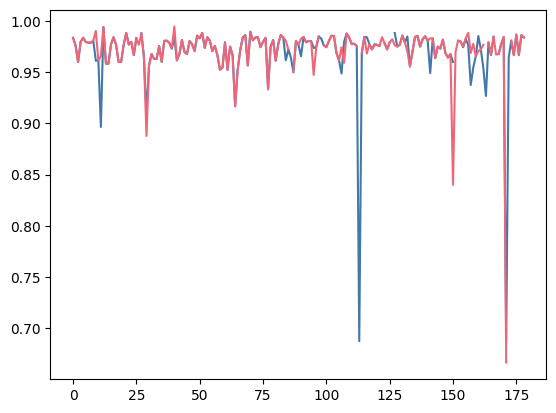

In [149]:
ax = result_groups["DwC-T~Data"]["metrics.procedural_effort_split"].plot()
result_groups["DwC-T~Author"]["metrics.procedural_effort_split"].plot(ax=ax)

<Axes: >

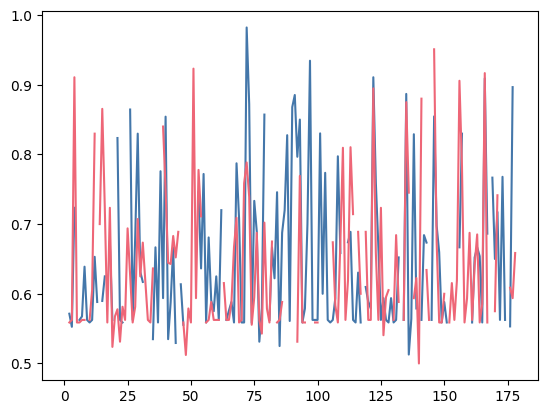

In [150]:
ax = result_groups["EML~Data"]["metrics.procedural_effort_split"].plot()
result_groups["EML~Author"]["metrics.procedural_effort_split"].plot(ax=ax)

In [151]:
for g,rs in result_groups.items():
    print(f"--- {g} ---")
    display(result_groups[g]["metrics.procedural_effort_split"].describe())

--- DwC-T~Data ---


count    174.000000
mean       0.969445
std        0.033698
min        0.686275
25%        0.966667
50%        0.976744
75%        0.982062
max        0.994118
Name: metrics.procedural_effort_split, dtype: float64

--- DwC-T~Author ---


count    174.000000
mean       0.971646
std        0.028347
min        0.666667
25%        0.967870
50%        0.976744
75%        0.982143
max        0.994624
Name: metrics.procedural_effort_split, dtype: float64

--- EML~Data ---


count    150.000000
mean       0.649512
std        0.109815
min        0.512821
25%        0.562500
50%        0.596875
75%        0.699419
max        0.982143
Name: metrics.procedural_effort_split, dtype: float64

--- EML~Author ---


count    148.000000
mean       0.636025
std        0.101443
min        0.500000
25%        0.562500
50%        0.593750
75%        0.687500
max        0.950820
Name: metrics.procedural_effort_split, dtype: float64

In [162]:
for g,rs in result_groups.items():
    print(f"--- {g} ---")
    display(
        pd.Series(
            itlx.chain.from_iterable(with_ok_constructed_trees(rs)["plan.replacement_context"].apply(itlx.chain.from_iterable).apply(list).tolist())
        ).value_counts().head(10)
    )

--- DwC-T~Data ---


archive[metadata]     175
field[term]            59
extension[rowType]      3
coreid[index]           1
Name: count, dtype: int64

--- DwC-T~Author ---


archive[metadata]     174
field[term]            33
extension[rowType]      2
Name: count, dtype: int64

--- EML~Data ---


para                          592
surName                       309
title                         257
descriptorValue               186
eml:eml[packageId]            146
userId                        145
instrumentation               137
maintenanceUpdateFrequency    129
metadata                       61
notes                          13
Name: count, dtype: int64

--- EML~Author ---


para                          575
surName                       301
title                         259
descriptorValue               192
userId                        147
eml:eml[packageId]            139
instrumentation               138
maintenanceUpdateFrequency    134
metadata                       75
notes                          11
Name: count, dtype: int64

In [163]:
for g,rs in result_groups.items():
    print(f"--- {g} ---")
    display(
        pd.Series(
            itlx.chain.from_iterable(with_ok_constructed_trees(rs)["plan.replacement_context"].apply(itlx.chain.from_iterable).apply(list).tolist())
        ).unique()
    )

--- DwC-T~Data ---


<StringArray>
['archive[metadata]', 'field[term]', 'extension[rowType]', 'coreid[index]']
Length: 4, dtype: str

--- DwC-T~Author ---


<StringArray>
['archive[metadata]', 'field[term]', 'extension[rowType]']
Length: 3, dtype: str

--- EML~Data ---


<StringArray>
[         'eml:eml[packageId]',                       'title',
                     'surName',                      'userId',
                        'para',             'instrumentation',
                        'role',             'descriptorValue',
  'maintenanceUpdateFrequency',                    'metadata',
                          'id',                        'name',
                     'license',             'provenanceNotes',
                'studyContext',                 'recordBasis',
              'provenanceNote',             'processingNotes',
                 'recordCount',                   'givenName',
            'organizationName',                       'notes',
                         'gap',           'provenanceSummary',
                'datasetTheme',           'collectionContext',
            'knownLimitations',                  'updateDate',
                'datasetScope',                  'dataSource',
          'samplingEventNotes',          

--- EML~Author ---


<StringArray>
[        'eml:eml[packageId]',                      'title',
                    'surName',                     'userId',
                       'para',            'instrumentation',
            'descriptorValue', 'maintenanceUpdateFrequency',
                   'metadata',      'methodologicalContext',
                'recordCount',                      'notes',
          'datasetScopeNotes',               'identifiedBy',
                'eml:purpose',             'provenanceNote',
                 'sourceFile',                   'rowCount',
           'temporalCoverage',         'geographicCoverage',
          'taxonomicCoverage',                    'context',
                 'provenance',               'sourceSystem',
          'collectionContext',            'provenanceNotes',
            'eml:eml[system]',      'geographicDescription',
                       'date',           'customExtensions',
                      'start',                        'end',
          

In [168]:
len(set.union(
    set(pd.Series(
        itlx.chain.from_iterable(
            with_ok_constructed_trees(result_groups["EML~Data"])[
                "plan.replacement_context"
            ].apply(itlx.chain.from_iterable).apply(list).tolist())
    ).unique().tolist())
    ,
    set(pd.Series(
        itlx.chain.from_iterable(
            with_ok_constructed_trees(result_groups["EML~Author"])[
                "plan.replacement_context"
            ].apply(itlx.chain.from_iterable).apply(list).tolist())
    ).unique().tolist())
))

115